<center><h1>Ejercicio_2</h1></center>
<center><h2>Hands-On Reinforcement Learning Applied to Trade Execution Algorithms</h2></center>
<center>
Autor: <cite><a href="https://www.linkedin.com/in/aoteog/">Oteo García, Alberto</a></cite>
</center>
<center>
Autor: <cite><a href="https://www.linkedin.com/in/jesus-sanz/">Sanz del Real, Jesús</a></cite>
</center>
<center><i>Notebook base del taller: <code>workshop/execution_lab.ipynb</code> · Réplica de <code>Ejercicio_1/Ejercicio_1.ipynb</code> · Entrega del <b>Ejercicio 2</b> (Taller de RL aplicado · MIAX, Módulo VI)</i></center>
<center><h3>Creación de un algoritmo de ejecución estilo TWAP</h3></center>
<center><b>PARTE 1</b> · Estado y sistema de recompensas &nbsp;&nbsp;|&nbsp;&nbsp; <b>PARTE 2</b> · Ajuste y motivación de los hiperparámetros</center>

----------------

## 0. Ejercicio 2 · enunciado, alcance y guía de lectura

**Enunciado (Ejercicio 2 · 3.5 puntos) — _Creación de un algoritmo de ejecución estilo TWAP_.** El ejercicio se compone de **dos partes igualmente importantes**:

| Parte | Lo que pide el enunciado | Dónde está en este notebook |
|---|---|---|
| **PARTE 1** | Modificar el sistema de recompensas para replicar el comportamiento de un TWAP. **Explicar qué variables se usan en el estado, cómo se define la recompensa y por qué.** Incluir gráficos con los resultados | **§2** (diseño del estado, diseño de la recompensa, entorno modificado, verificación **antes** de entrenar y primer entrenamiento con gráficos) |
| **PARTE 2** | Para asegurar un correcto entrenamiento, ajustar la parametría (γ, tamaño del buffer, etc.) **y motivar** las decisiones | **§3** (protocolo, hipótesis previas, barridos de hiperparámetros sobre datos de validación, decisión motivada, entrenamiento final, resultados en *train* y comprobación de que funciona con distintos días, horas, duraciones y tamaños de orden) |

**Requisitos y simplificaciones del enunciado, y cómo se cumplen**

| Requisito | Cómo se cumple |
|---|---|
| Órdenes hijas de 1 título; orden CARE con tamaño alineado (p. ej. 400 steps → 40 títulos = 1 de cada 10) | Ya lo hacía el entorno del Ejercicio 1: `vol_care = int(U(7.5 %, 12.5 %) · episode_bins)` títulos, es decir, una compra cada 8–13 steps. Se mantiene |
| Sin impacto de mercado ni costes de transacción | Igual que en el Ejercicio 1: nuestras órdenes no mueven el libro |
| No se pide una réplica exacta, pero sí un comportamiento similar al de `images/twap_model/twap_reproduction_dqn.png` | §2.1 define **cinco criterios cuantificables** de «comportamiento similar» y §3 los comprueba; la imagen de referencia se muestra y se compara con los resultados |
| No es necesaria validación; basta con imágenes correctas en *train* | Hay imágenes en *train* (§2.6 y §3.7). Además, y sin que sea obligatorio, la selección de hiperparámetros se hace sobre *validation* y se comprueba en *test* (§3.8) |
| Debe funcionar para distintos días, momentos, duraciones y tamaños de orden | `reset()` ya sortea los cuatro; §3.8 lo demuestra con cientos de episodios y mide si el error depende de la duración o del tamaño |
| Basta con un activo (SAN o REP) | Repsol (`data/rep_data.pkl`), como en el Ejercicio 1 |

### Convenio para marcar los bloques

Este notebook es una **réplica del Ejercicio 1**, que es su base. Por eso las marcas indican el cambio **respecto al Ejercicio 1** (los cambios del Ejercicio 1 respecto a `execution_lab.ipynb` están documentados en su propio notebook):

| Marca | Significado |
|---|---|
| 🟢 **SIN CAMBIOS** | Bloque idéntico al del Ejercicio 1 |
| 🔧 **BLOQUE MODIFICADO** | Bloque del Ejercicio 1 que se ha cambiado para este ejercicio. Dentro del código, las líneas tocadas llevan un comentario que empieza por `# 🔧` |
| ➕ **BLOQUE AÑADIDO** | Celda nueva que no existía en el Ejercicio 1. En el código, las líneas nuevas dentro de un bloque modificado llevan `# ➕` |

Las celdas de texto originales del taller (resumen, descripción de los datos, glosario de parámetros…) se conservan sin modificar.

### Decisiones generales

* **Activo y datos:** Repsol. *Train*: 60 primeros días hábiles de 2018 (se entrena y se muestran las imágenes) · *Validation*: 30 primeros de 2019 (se usa para **elegir** los hiperparámetros: así no se seleccionan sobre los mismos datos con los que se entrena) · *Test*: días 31–60 de 2019 (solo comprobación final).
* **Algoritmo:** Double DQN (red *primary* + red *target*, *Combined Experience Replay*, ε-greedy), el `DDQNAgent` del repositorio. Se añade una subclase **numéricamente equivalente pero más rápida** (§2.6) para que sea abordable hacer decenas de entrenamientos en la Parte 2.
* **Entorno de ejecución:** local, **sin Docker** (Python 3.13 · TensorFlow 2.21 con Keras 3 · pandas 2.3.3 · numpy 2.3.5), igual que en el Ejercicio 1.
* **Lo que no cambia respecto al Ejercicio 1:** el generador de episodios, el cálculo del VWAP de mercado, las acciones (esperar / comprar 1 título al `ask1`), las condiciones de fin de episodio y la política de exploración aleatoria. Solo cambian **la recompensa** y **el estado** (más la recompensa final, que antes valía 0), que son justo lo que pide el ejercicio.

### La solución en breve

| | |
|---|---|
| **Estado** | `[time_left, vol_left, lag]`: tiempo restante, volumen restante y **retraso respecto al calendario lineal medido en órdenes hijas** (§2.2) |
| **Recompensa** | `r_t = −\|títulos ejecutados − calendario lineal\|` tras cada step, más una recompensa final si la orden se completa antes de tiempo (§2.3). **No usa el precio** |
| **Por qué replica un TWAP** | Su política óptima exacta (programación dinámica, §2.5) es «comprar si vamos más de ½ título por detrás del calendario»: compras equiespaciadas y orden completa al final del episodio |
| **Con los hiperparámetros del Ejercicio 1** | El entrenamiento no converge (la pérdida llega a 10⁵ y la orden no se completa nunca): problema de optimización, no de diseño (§2.6) |
| **Hiperparámetros elegidos (Parte 2)** | `gamma = 0.95` · aprender cada 8 steps · buffer 20 000 · `alpha = 1e-3` · 32 neuronas · 200 episodios; decididos con 17 entrenamientos sobre datos de validación (§3.2–§3.4) |
| **Resultado (*test*, 100 episodios)** | **Completa el 100 % de las órdenes**, usa el 98.9 % del tiempo y sigue el calendario con un error del **0.54 %** de la orden (el mínimo teórico con títulos enteros es ≈ 0.5 %; el TWAP del Ejercicio 1: 0.87 %). *Slippage* frente al VWAP idéntico al del TWAP (1.45 vs 1.46 bps). Resultado idéntico con otras dos semillas (§3.8) |

### Registro de cambios respecto al Ejercicio 1

| Nº | Bloque | Tipo | Qué se ha hecho | Por qué |
|---|---|---|---|---|
| 1 | Título | 🔧 | Título **Ejercicio_2** y subtítulo con las dos partes | Pedido |
| 2 | §0 Introducción y este registro | ➕ | Enunciado de las dos partes, requisitos y convenio | Exigido: especificar los bloques modificados y la lógica seguida |
| 3 | §1 Imports, carga de datos y exploración | 🟢 | Sin cambios (incluye el cargador compatible con pandas ≥ 2.1) | El problema y los datos son los mismos |
| 4 | §2.4 `BestExecutionEnv.__init__` | ➕ | Argumento `state_mode` (`"basic"` = estado del Ejercicio 1, `"schedule"` = el nuevo) y constante `LAG_CLIP` | Permite la **ablación** del estado (§3.4) sin tocar nada más |
| 5 | §2.4 `observation_builder` | 🔧 | Tercera variable del estado: `lag`, retraso respecto al calendario lineal medido en órdenes hijas | Es la variable de decisión de un TWAP (§2.2) |
| 6 | §2.4 `_compute_reward` | 🔧 | `reward = −\|ejecutado − calendario lineal\|` (en títulos). Sustituye al VWAP *slippage* en bps | Replicar un TWAP (§2.3). La recompensa del Ejercicio 1 tiene como óptimo no operar |
| 7 | §2.4 `_compute_done_reward` | 🔧 | Si la orden se completa antes de tiempo, se carga la desviación que habría acumulado el resto del episodio. Antes valía 0 | Que terminar antes no sirva para «escapar» de las penalizaciones; hace que el óptimo exacto sea el TWAP (§2.5) |
| 8 | §2.4 `step()` | ➕ | La recompensa final también se suma al último elemento de `reward_hist` | Que `reward_hist` recoja el retorno completo del episodio |
| 9 | Resto de `BestExecutionEnv` | 🟢 | Sin cambios | — |
| 10 | §2.5 Verificación | 🔧 / ➕ | Invariantes adaptados a la nueva recompensa y estado; traza de un episodio; ranking de políticas de referencia; **comprobación por programación dinámica** de que el óptimo de la recompensa es el TWAP | Demostrar que la recompensa pide lo que queremos *antes* de entrenar nada |
| 11 | §2.5 `TWAP.act` | 🔧 | Lee `s[0], s[1]` (el estado ahora tiene 3 variables); lógica idéntica | Compatibilidad con el nuevo estado |
| 12 | §2.5 `episode_metrics` | 🔧 | Nuevas métricas de fidelidad al calendario: error medio (% de la orden), desvío máximo y regularidad de las compras | Cuantificar «comportamiento similar a un TWAP» |
| 13 | §2.6 `FastDDQNAgent` | ➕ | Subclase de `DDQNAgent` con inferencia en numpy y paso de gradiente compilado. **Mismo algoritmo**, verificado numéricamente contra el original | ~4× más rápido por *learn*; permite la Parte 2. Además devuelve la pérdida real de cada batch (ver nota en §2.6) |
| 14 | §2.6 `train_agent` | ➕ | El bucle del Ejercicio 1 (relleno de buffer → `reset/act/step/experience/learn/update_target` → ε) empaquetado en una función con una configuración | Reutilizarlo en el primer entrenamiento, los barridos y el entrenamiento final sin copiar código |
| 15 | §2.6 Primer entrenamiento | ➕ | Entrenamiento con **los hiperparámetros del Ejercicio 1** y gráficos | Resultado de la Parte 1 y punto de partida de la Parte 2 |
| 16 | §3 PARTE 2 completa | ➕ | Protocolo, hipótesis, barridos, decisión, entrenamiento final, gráficos de *train*, generalización y robustez | Es la Parte 2 del enunciado |
| 17 | §4 Conclusiones | ➕ | Resumen, interpretación y límites | Motivación exigida por el enunciado |

<center><h1>Resumen</h1></center>

<center>

<p style="width:80%">
    En este notebook se presenta el taller de aprendizaje por refuerzo aplicado a un caso real para finanzas. 
    El objetivo es plantear, desde cero, la resolución del problema de <b>algoritmos de ejecución</b> a través del uso
    de técnicas de aprendizaje por refuerzo. Para ello, durante el taller se ha de completar el entorno básico <b>BestExecutionEnv</b> donde los asistentes desarrollarán las partes claves del
    código para obtener un simulador de mercado que, aunque relativamente naive, será funcional. Posteriormente, los participantes tendrán que aplicar algoritmos clásicos y basados en inteligencia artificial (IA) para la
    resolución del problema. 
</p>
<p style="width:80%">
    En términos sencillos, el problema de <b>algoritmos de ejecución</b> trata sobre la ejecución de órdenes con un tamaño lo suficientemente grande como para que su ejecución suponga un <b><i>'problema'</i></b>, como se ha comentado durante la explicación del caso práctico. La resolución de la ejecución de estas órdenes (órdenes CARE) se puede realizar utilizando diferentes aproximaciones. En el caso de este taller, queremos optimizar el <b><i>timing</i></b> de nuestras órdenes para minimizar el impacto de mercado. Es decir, buscaremos trocear la orden CARE para comprar (vender) a los menores (mayores) precios de la sesión en la que se ejecuta la orden CARE. Como baseline para saber si nuestra ejecución es buena, o mala, utilizaremos el baseline habitual en el sector: el VWAP slippage.
</p> 
<p style="width:80%">
El VWAP slippage es la desviación, en puntos básicos, del VWAP del mercado en comparación con el VWAP de nuestro algoritmo. Siendo el VWAP el precio medio ponderado por el volumen:
</p>   
    
$$\frac{\sum_{i=1}^T p_i\cdot v_i}{\sum_{i=1}^Tv_i}$$

</center>

---

<center><h1>Datos</h1></center>

<center>
<p style="width:80%">
Los datos para este taller se han extraído de los activos Repsol y Santander (<i>rep_data.pkl</i> y <i>san_data.pkl</i>). Entre la información extraída contamos con la primera posición del libro de órdenes, tanto del bid como del ask, así como el volumen acumulado, todo ello realizando una agrupación por 5 segundos. Las sesiones extraidas del libro de órdenes están comprendidas entre las 13:00h y las 17:25h. El conjunto de datos está partido en 3 subconjuntos, para los siguientes días bursátiles:
</p>
    
</center> 
<center>
    <p style="width:35%"><b>Train</b>: Primeros 60 días hábiles de 2018</p>
    <p style="width:35%"><b>Validación</b>: Primeros 30 días hábiles de 2019</p>
    <p style="width:35%"><b>Test</b>: Intervalo de los días hábiles del 31 al 60 de 2019 (30 días)</p>
</center>

<center>
<p style="width:80%">
<b>Adicionalmente</b>, para aquellos que quieran aumentar el grado de detalle, se han añadido otros dos ficheros con información más completa del libro de órdenes y de las ejecuciones de mercado. El fichero <i>orderbook.pkl</i> contiene las posiciones (precios y volúmenes) de hasta la tercera posición del libro de órdenes, agrupados por 5 segundos; el fichero <i>executions.pkl</i> todas las ejecuciones del mercado. En ambos casos, se trata de información para la compañía Repsol, entre las 13:00h y 17:25h de la sesión. El conjunto de datos está partido en 3 subconjuntos, para los siguientes días bursátiles:
</p>
    
</center> 
<center>
    <p style="width:35%"><b>Train</b>: Primeros 40 días hábiles de 2019</p>
    <p style="width:35%"><b>Validación</b>: Intervalo del 41 al 60 de 2019 (20 días)</p>
    <p style="width:35%"><b>Test</b>: Intervalo del 61 al 80 de 2019 (20 días)</p>
</center>

---
## 1. Preparación del entorno de trabajo y de los datos

> 🟢 **SIN CAMBIOS** — esta sección es idéntica a la del Ejercicio 1: mismos imports, mismo cargador de los `.pkl` (compatible con pandas ≥ 2.1) y misma exploración de datos. Se conserva completa para que el notebook se pueda leer y ejecutar de forma independiente.

### 1.1 Imports

In [1]:
import os
# Solo cosmético, y debe ir ANTES de importar TensorFlow: silencia los avisos informativos de oneDNN/TF.
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import pickle
import random
import sys
import warnings
from pathlib import Path
from typing import Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Aviso de numpy al deserializar los .pkl antiguos (numpy.core -> numpy._core). Es inocuo.
warnings.filterwarnings("ignore", category=DeprecationWarning)

# Localiza la raíz del repo (la carpeta que contiene src/ y data/) esté donde esté el notebook.
#    Sustituye al `sys.path.append("..")` comentado del original y evita depender del directorio de trabajo.
def find_repo_root() -> Path:
    for p in [Path.cwd(), *Path.cwd().parents]:
        for cand in (p, p / "best-execution"):
            if (cand / "src" / "agents" / "dqn.py").exists():
                return cand
    raise FileNotFoundError("No se encuentra la raíz del repo (carpeta con src/agents/dqn.py)")

REPO_ROOT = find_repo_root()
sys.path.append(str(REPO_ROOT))

from src.agents.dqn import DDQNAgent
from src.report.report import plot_results

# Reproducibilidad
import tensorflow as tf
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.get_logger().setLevel("ERROR")   # cosmético: sin el aviso de «GPU no disponible en Windows nativo»

print(f"Raíz del repo : {REPO_ROOT}")
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | TensorFlow {tf.__version__}")

Raíz del repo : C:\Users\Joseph\Documents\MIAX\Modulo VI\Taller Aplicacio RL\best-execution
Python 3.13.7 | numpy 2.3.5 | pandas 2.3.3 | TensorFlow 2.21.0


### 1.2 Carga de datos

In [2]:
# Datos disponibles: san_data.pkl y rep_data.pkl
# Carga compatible con pandas 1.x y 2.x
from pandas._libs.internals import BlockPlacement
import pandas.core.internals.blocks as pd_blocks


class _CompatUnpickler(pickle.Unpickler):
    """Deserializa .pkl creados con pandas 1.x en pandas >= 2.1."""

    def find_class(self, module, name):
        if module == "pandas.core.internals.blocks" and name == "new_block":
            def _new_block(values, placement, ndim=None, *args, **kwargs):
                if not isinstance(placement, BlockPlacement):
                    placement = BlockPlacement(placement)
                return pd_blocks.new_block(values, placement, ndim=ndim, *args, **kwargs)
            return _new_block
        return super().find_class(module, name)


def load_pickle_compat(path):
    try:
        with open(path, "rb") as f:
            return pickle.load(f)                   # camino normal (el del original)
    except TypeError:
        with open(path, "rb") as f:
            return _CompatUnpickler(f).load()       # fallback para pandas >= 2.1


dict_ = load_pickle_compat(REPO_ROOT / "data" / "rep_data.pkl")
dict_.keys()

dict_keys(['train', 'val', 'test'])

### 1.3 Exploración de los datos

In [3]:
data = dict_["train"]   # línea original: el entorno se entrena con los 60 días de train (2018)

# Resumen legible en lugar de volcar el diccionario completo
days = list(data.keys())
print(f"train: {len(days)} días ({days[0]} → {days[-1]}) | columnas: {list(data[days[0]].columns)}")
display(data[days[0]].head())


def resumen_split(split: dict) -> dict:
    dfs = list(split.values())
    spread_bps = pd.concat([(d["ask1"] - d["bid1"]) / ((d["ask1"] + d["bid1"]) / 2) * 1e4 for d in dfs])
    vol = pd.concat([d["cumvol"].diff().dropna() for d in dfs])
    vol_pos = vol.clip(lower=0)
    top1 = vol_pos.sort_values(ascending=False).head(int(len(vol_pos) * 0.01)).sum() / vol_pos.sum()
    return {
        "días": len(dfs),
        "bins por día (mín–máx)": f"{min(map(len, dfs))}–{max(map(len, dfs))}",
        "spread medio (bps)": round(spread_bps.mean(), 2),
        "volumen medio por bin (títulos)": round(vol.mean()),
        "% de bins sin volumen": round((vol == 0).mean() * 100, 1),
        "% del volumen en el 1 % de bins": round(top1 * 100, 1),
        "incrementos negativos de cumvol": int((vol < 0).sum()),
    }


display(pd.DataFrame({name: resumen_split(split) for name, split in dict_.items()}))

train: 60 días (2018-01-02 → 2018-03-26) | columnas: ['ask1', 'bid1', 'vask1', 'vbid1', 'last', 'cumvol', 'date']


,ask1,bid1,vask1,vbid1,last,cumvol,date
time,,,,,,,
2018-01-02 13:00:00,15.00,14.995,1368.0,1878.0,15.000,1429424.0,2018-01-02
2018-01-02 13:00:05,15.01,15.005,1308.0,1.0,15.000,1430792.0,2018-01-02
2018-01-02 13:00:10,15.01,15.000,2988.0,5438.0,15.005,1431776.0,2018-01-02
2018-01-02 13:00:15,15.01,15.000,2158.0,7941.0,15.005,1431776.0,2018-01-02
2018-01-02 13:00:20,15.01,15.000,2138.0,10009.0,15.005,1431978.0,2018-01-02


,train,val,test
días,60,30,30
bins por día (mín–máx),3177–3181,3179–3181,3179–3181
spread medio (bps),4.68,4.29,4.12
volumen medio por bin (títulos),1002,1047,738
% de bins sin volumen,76.3,77.1,82.1
% del volumen en el 1 % de bins,64.5,66.6,68.6
incrementos negativos de cumvol,2,0,0


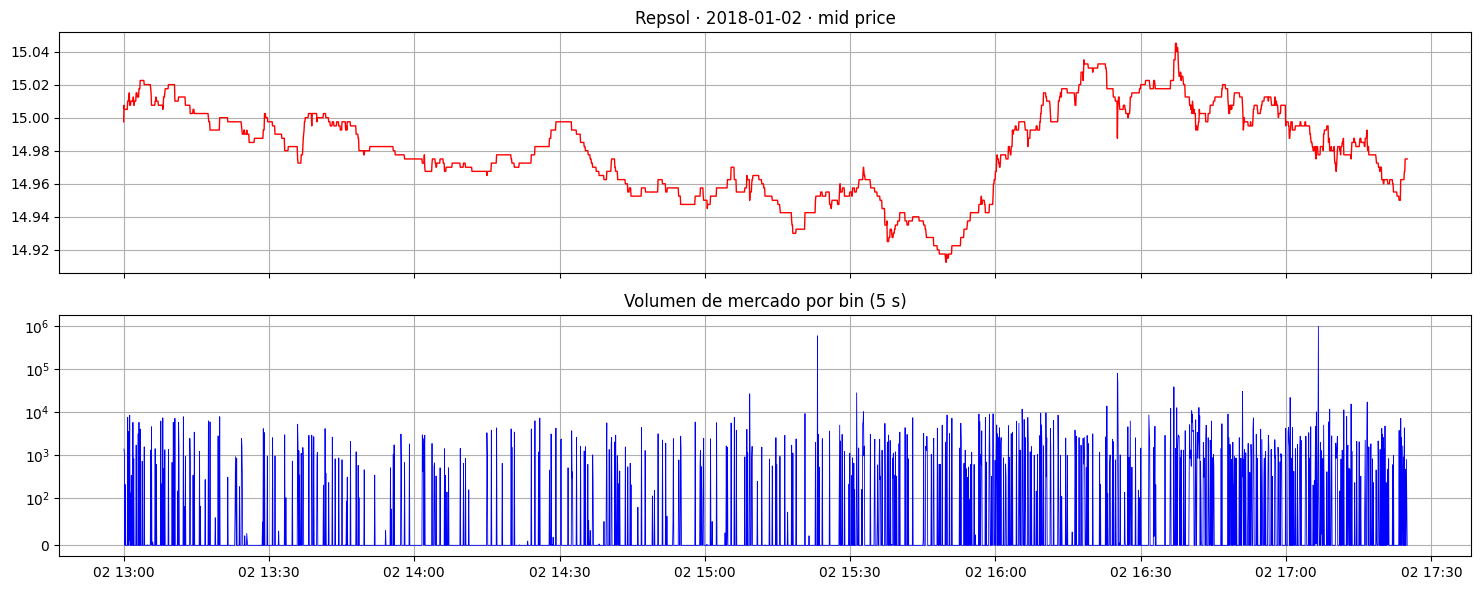

In [4]:
# Un día de ejemplo: mid price (arriba) y volumen negociado por bin de 5 s (abajo, escala symlog)
d = data[days[0]]
vol_bin = d["cumvol"].diff().clip(lower=0)
fig, ax = plt.subplots(2, 1, figsize=(15, 6), sharex=True)
ax[0].plot((d["ask1"] + d["bid1"]) / 2, color="red", lw=1)
ax[0].set_title(f"Repsol · {days[0]} · mid price"); ax[0].grid(True)
ax[1].plot(vol_bin, color="blue", lw=0.6)
ax[1].set_yscale("symlog", linthresh=100); ax[1].set_title("Volumen de mercado por bin (5 s)"); ax[1].grid(True)
plt.tight_layout(); plt.show()

**Lo que enseñan los datos y por qué importa para el entorno**

* Cada día es un `DataFrame` con un *bin* cada 5 s entre las 13:00 y las 17:25 (≈ 3 180 filas; algunos días tienen unos pocos bins menos, por eso el entorno indexa por posición y valida la longitud del episodio).
* El **volumen está extremadamente concentrado**: la mediana por bin es 0 y una fracción minúscula de bins concentra una parte muy grande del volumen total (cruces/bloques). Consecuencia: el VWAP de un episodio puede estar dominado por muy pocos *prints* y es un *benchmark* ruidoso → la recompensa heredará ese ruido.
* El volumen acumulado (`cumvol`) tiene **incrementos negativos** en *train* (correcciones de datos). No tienen sentido como volumen, así que el entorno los recorta a 0 (cambio nº 8 del registro del Ejercicio 1; el entorno ya lo hace).
* El *spread* medio ronda los 4 bps: comprar siempre en `ask1` cuesta, de media, la mitad del *spread* respecto al *mid*. Esto será clave para interpretar la recompensa.

---
# PARTE 1 · Estado y sistema de recompensas para replicar un TWAP

## 2. Parte 1

**Qué se hace en esta parte, en orden:** (§2.1) definir con precisión qué comportamiento hay que replicar → (§2.2) elegir las variables del estado y justificarlas → (§2.3) diseñar la recompensa y justificarla → (§2.4) implementarlas en el entorno → (§2.5) **comprobar, antes de entrenar nada**, que la recompensa pide lo que queremos (incluida una demostración por programación dinámica de que su óptimo exacto es un TWAP) → (§2.6) entrenar por primera vez, con los hiperparámetros del Ejercicio 1, y mostrar los primeros resultados con gráficos.

### 2.1 Qué hay que replicar: el comportamiento de un TWAP

Un **TWAP** (*time-weighted average price*) reparte la orden **de forma uniforme en el tiempo, sin mirar al mercado**. Con órdenes hijas de 1 título, una orden CARE de `C` títulos y un episodio de `B` bins de 5 s, el calendario es lineal: tras `k` steps deben llevarse ejecutados `C·k/B` títulos, es decir, **una compra cada `B/C` steps** (≈ 10 steps con la participación del 7.5 %–12.5 % de este problema).

El enunciado aporta una imagen de referencia de lo que se pretende conseguir:

![Gráfico de referencia del enunciado: TWAP reproducido con un DQN](../images/twap_model/twap_reproduction_dqn.png)

Lo que se ve en ella (y que es la definición operativa de «comportamiento similar» que se usará en todo el notebook):

1. El volumen acumulado del algoritmo (línea naranja, panel inferior) es **una escalera casi recta de 0 % a 100 %** que termina justo al final del episodio.
2. Las compras (barras naranjas) están **equiespaciadas** y no dependen de cuándo negocia el mercado (barras azules): el mercado puede concentrar el 80 % de su volumen en un instante y el algoritmo ni se inmuta.
3. Como consecuencia, el VWAP del algoritmo (panel superior) acompaña al del mercado, sin intentar batirlo.

Se traduce en **cinco criterios cuantificables**, que se miden con `episode_metrics` (§2.5) en todas las evaluaciones:

| Criterio | Métrica | Valor de un TWAP ideal |
|---|---|---|
| C1 · completa la orden | % de episodios con la orden completa | 100 % |
| C2 · usa casi todo el tiempo | % del episodio consumido | ≈ 99 % (la última compra cae en la última «porción» de `B/C` steps) |
| C3 · sigue el calendario lineal | error de seguimiento medio, en % de la orden | ≈ `1/(4C)` ≈ 0.5 %: el mínimo que permiten los títulos enteros |
| C4 · compras equiespaciadas | coeficiente de variación de la separación entre compras | ≈ 0 (algo mayor por el redondeo de `B/C`) |
| C5 · independiente del mercado | *slippage* medio frente al VWAP | el mismo que el de un TWAP |

### 2.2 Diseño del estado: qué variables y por qué

Notación: `B` = bins del episodio, `C` = títulos de la orden CARE, `t` = steps ya consumidos, `e` = títulos ya comprados.

| Variable | Definición | Rango | Qué cuenta |
|---|---|---|---|
| `time_left` | `(B − t) / B` | (0, 1] | cuánto tiempo queda |
| `vol_left` | `(C − e) / C` | [0, 1] | cuánto volumen falta |
| **`lag`** (nueva) | `clip( (C·(t+1)/B − e) / 5 , −1, 1 )` | [−1, 1] | **cuántas órdenes hijas vamos por detrás del calendario lineal** al terminar este step (positivo = por detrás, negativo = por delante), recortado a ±5 órdenes |

**Por qué estas variables**

* `time_left` y `vol_left` son el **estado privado mínimo y markoviano** de cualquier orden de ejecución (lo que se eligió en el Ejercicio 1): lo único que hace falta para saber «cuánto me queda y de cuánto tiempo dispongo». Están normalizadas, así que no dependen del activo, del precio ni del tamaño del episodio.
* Un TWAP solo hace una cosa: **comparar lo ejecutado con el calendario** y comprar si va por detrás. La información que necesita es, por tanto, el **desfase** `lag = C·(vol_left − time_left) + C/B`. Se puede calcular a partir de las dos variables anteriores, pero se da **explícita** por dos motivos:
  1. *Resolución.* La decisión se juega a **media orden hija**: hay que comprar cuando el retraso supera ½ título, es decir, ≈ 0.01 en las variables normalizadas (y distinto en cada episodio porque `C` cambia). Con solo `time_left` y `vol_left` la red tendría que aprender a restar dos entradas con una precisión del 1 % y a reescalar ese umbral según `C`.
  2. *Invariancia.* Medido **en órdenes hijas**, el umbral de decisión es siempre el mismo (`lag > ½`) para cualquier `C` y cualquier `B`. El agente aprende **una** regla que sirve para todos los tamaños y duraciones. (§3.4 hace la prueba: con el mismo presupuesto, el agente con solo `time_left` y `vol_left` no aprende.)
* El recorte a ±5 no pierde información útil: con más de 5 órdenes de retraso la acción óptima ya es obvia (comprar), y con más de 5 de adelanto también (esperar). Mantiene las entradas en [−1, 1].

**Qué *no* entra en el estado, y por qué.** Ni precio, ni *spread*, ni volumen de mercado, ni desequilibrio del libro. Un TWAP es **por definición independiente del mercado**: no tiene que mirarlo. Añadir esas variables aumentaría la dimensión del problema y daría al agente la oportunidad de sobreajustar a patrones de días concretos, justo lo contrario de lo que se busca. Se incorporarán en el Ejercicio 4 (Idea A) cuando el objetivo sea **mejorar** al TWAP y no replicarlo.

*Sin fuga de información:* el VWAP del episodio (que usa datos futuros) sigue sin estar en el estado; en este ejercicio ni siquiera interviene en la recompensa.

### 2.3 Diseño de la recompensa: cómo se define y por qué

**Definición.** Tras la acción del step `t` (con `e_{t+1}` títulos ya comprados):

$$ r_t \;=\; -\,\Big|\; e_{t+1} \;-\; C\cdot\frac{t+1}{B} \;\Big| \qquad\text{(en títulos)} $$

Es **menos la desviación absoluta entre lo ejecutado y el calendario lineal**. Y si la orden se completa antes de agotar el tiempo, en el último step se suma además la desviación que se habría acumulado durante los steps que quedaban (con la orden ya completa, el calendario sigue avanzando):

$$ r_{\text{final}} \;=\; -\sum_{j=t_{\text{fin}}+1}^{B-1} \Big|\, C - C\cdot\frac{j+1}{B} \Big| $$

Si el episodio termina por tiempo, la recompensa final vale 0. Maximizar el retorno equivale a **minimizar el error de seguimiento acumulado** respecto a un TWAP.

**Por qué esta recompensa**

1. **Es el comportamiento que se quiere.** Las diapositivas dicen que *«la recompensa debe guardar relación con el objetivo»* y citan entre los componentes posibles la *«desviación con respecto al plan tradicional»*. El plan tradicional es, aquí, el TWAP.
2. **Es densa.** Da información en **cada step**. Una recompensa solo terminal («al final, cuánto te has desviado») obligaría a repartir el mérito entre ~500 decisiones (*sparse reward*).
3. **Su óptimo es exactamente un TWAP.** Comprar en un step mueve la desviación en +1 título: compensa si y solo si el agente va **más de ½ título por detrás** (`lag > ½`). Eso produce compras equiespaciadas cada `B/C` steps. §2.5 lo comprueba de dos formas: con una política que aplica esa regla y con programación dinámica exacta.
4. **La unidad es el título.** La diferencia entre comprar y esperar es siempre ±1, sea cual sea `C` o `B`: la señal tiene la misma escala en todos los episodios y las recompensas son O(1), cómodas para el MSE de la red.
5. **Valor absoluto y no cuadrado.** Ambos tienen el mismo umbral de decisión, pero con el valor absoluto la señal marginal es constante (±1) incluso cuando se está cerca del calendario, que es donde hay que decidir bien; con el cuadrado se desvanece justo ahí.
6. **No usa el precio.** Como el TWAP. Así no hay ningún incentivo a hacer *timing* de mercado: el algoritmo no puede (ni debe) intentar batir al VWAP. La mejora de resultados es el Ejercicio 4.
7. **La recompensa final evita un atajo.** Sin ella, terminar la orden antes de tiempo **corta** las penalizaciones futuras y el óptimo exacto compra la última orden unos steps antes que el TWAP. La programación dinámica de §2.5 lo cuantifica: sin recompensa final el óptimo coincide con la regla del TWAP solo en el 84–96 % de los estados relevantes; con ella, en el 100 %.

**Alternativas consideradas y descartadas**

| Alternativa | Por qué no |
|---|---|
| VWAP *slippage* (la del Ejercicio 1) | Su óptimo es **no operar** (se demostró en el Ejercicio 1) y, aunque lo evitase, un TWAP no persigue precio: compra en un calendario |
| *Slippage* + premio por completar | Mezcla dos objetivos; el resultado sería una política que *intenta* batir al VWAP, no un calendario regular |
| «Imitación»: +1 si la acción coincide con la del TWAP, −1 si no | Es aprendizaje supervisado disfrazado: el TWAP entra en la recompensa como oráculo, así que el agente solo copia una regla en lugar de descubrirla a partir de un objetivo. Además da una señal binaria, menos informativa que la distancia al calendario |
| Solo recompensa terminal (desviación final) | Escasa (*sparse*): un episodio entero para una sola señal |
| Desviación al cuadrado | Mismo óptimo, pero la señal se desvanece cerca del calendario (punto 5) |

### 2.4 El entorno con el nuevo estado y la nueva recompensa

Solo se tocan cuatro métodos de `BestExecutionEnv` (más el argumento del constructor). **Todo lo demás es idéntico al Ejercicio 1.**

> 🔧 **BLOQUE MODIFICADO** — (a) `__init__`: argumento `state_mode` y constante `LAG_CLIP` (➕); (b) `observation_builder`: tercera variable `lag` (🔧); (c) `_compute_reward`: desviación respecto al calendario lineal en lugar del VWAP *slippage* (🔧); (d) `_compute_done_reward`: desviación del resto del episodio si la orden se completa antes de tiempo (🔧); (e) `step()`: la recompensa final también se anota en `reward_hist` (➕). Las líneas tocadas llevan `# 🔧` / `# ➕`.

In [5]:
class BestExecutionEnv:

    # ➕ El retraso respecto al calendario que ve el agente se recorta a ±5 órdenes hijas (ver observation_builder)
    LAG_CLIP = 5.0

    def __init__(self, data, look_back=60, state_mode="schedule"):  # 🔧 nuevo argumento state_mode
        """Inicialización de la clase del entorno que simula
        el libro de ordenes.
        ----------------------------------------------------
        Input:
            - data:
                Dataframe con los datos previamente
                agrupados del libro de órdenes.

            - look_back:
                Ventana para la generación de features
                roladas en el instante t=0 del episodio.
                Esta ventana representa el rango máximo para
                la construcción de features.

            - state_mode:   (➕ Ejercicio 2)
                "basic":    estado del Ejercicio 1 -> [time_left, vol_left]
                "schedule": basic + retraso respecto al calendario lineal
                            -> [time_left, vol_left, lag]
        ----------------------------------------------------
        Variables Internas:
            - episode_bins:
                Número de bines (steps) del episodio.
            - episode_full_len:
                Es igual a look_back + episode_bins.
            - vol_care:
                Volumen total (en títulos) de la orden care.
            - actions_fn:
                Diccionario con las posibles acciones del agente.
                Las claves acceden a la función que evalúa la acción
                tomada por el agente.
            - n_actions:
                Número de acciones posibles.
            - n_features:
                Número de características de los estados.
            - episode:
                Dataframe que contiene los steps y estados del episodio.
            - episode_full:
                Es el episode añadiendo el look_back antes del comienzo
                del episodio.
            - episode_vwap:
                VWAP de mercado al final del episodio.
            - market_ep_vol:
                Volumen (títulos) ejecutado por el mercado en cada bin del episodio.
            - state_pos:
                Número de step en el que nos encontramos.
            - exec_vol:
                Acumulado de títulos ejecutados por el algoritmo.
            - actions_hist:
                Lista de acciones tomadas por el algoritmo en cada step.
            - market_vwap_hist:
                Lista de VWAP de mercado en cada step.
            - reward_hist:
                Lista de rewards obtenidas en cada step.
            - price_hist:
                Lista de precios ejecutados en cada step.
            - vol_hist:
                Lista de títulos ejecutados en cada step.
        """

        # Fixed params
        self.data = data
        self.look_back = look_back
        assert state_mode in ("basic", "schedule")   # ➕ debe fijarse antes de _detect_num_feat()
        self.state_mode = state_mode                 # ➕
        self.episode_bins = None
        self.episode_full_len = None
        self.vol_care = None

        self.actions_fn = {
            0: self._do_nothing,
            1: self._agg_action,
        }

        self.n_actions = len(self.actions_fn)
        self.n_features = self._detect_num_feat()

        # Data variables
        self.episode = None
        self.episode_full = None

        # Env variables
        self.episode_vwap = None
        self.market_ep_vol = None
        self.state_pos = 0
        self.exec_vol = 0
        self.actions_hist = []
        self.algo_vwap_hist = []
        self.market_vwap_hist = []
        self.reward_hist = []
        self.price_hist = []
        self.vol_hist = []

    def _detect_num_feat(self):
        """Detecta el número de variables del estado.
        Función necesaria para adaptarse automaticamente a los
        cambios en las variables de observation_builder.
        """
        self._reset_env_episode_params()
        self._generate_episode()
        s = self.observation_builder()
        return s.shape[0]

    def _reset_env_episode_params(self):
        """
        Reset del episodio e inicialización de los parámetros.
        Las variables internas vuelven a sus valores originales.
        """
        self.episode_full_len = None
        self.episode = None
        self.episode_full = None
        self.episode_vwap = None
        self.market_ep_vol = None
        self.state_pos = 0
        self.algo_vwap = 0
        self.exec_vol = 0
        self.actions_hist = []
        self.algo_vwap_hist = []
        self.market_vwap_hist = []
        self.reward_hist = []
        self.price_hist = []
        self.vol_hist = []

    def _generate_episode_params(self):
        """(1) Se determinan las características de la orden a ejecutar.
        La orden queda definida por:
         - episode_bins:
             Obtención de un número entero aleatorio [400, 600]
             con una distribución uniforme.
         - vol_care:
             Obtención del porcentaje de steps en el que hay que
             ejecutar una orden para cubrir la orden care.
             vol_care responde a un valor uniforme [0.075, 0.125]
             multiplicado por el número self.episode_bins.
             Lo convertimos a entero.
        """
        # Int aleatorio entre 400 y 600 (ambos incluidos) como un objeto numpy.
        #    np.random.randint excluye el extremo superior -> 601.
        self.episode_bins = np.random.randint(400, 601)
        # Float aleatorio uniforme entre 0.075 y 0.125 (fracción de steps en los que hay que comprar)
        pct_bins = np.random.uniform(0.075, 0.125)
        # Tamaño de la orden CARE en títulos = pct_bins * episode_bins, truncado a int
        #    (órdenes hijas de 1 título -> vol_care = nº de acciones agresivas necesarias)
        self.vol_care = int(pct_bins * self.episode_bins)

        self.episode_full_len = self.episode_bins + self.look_back

        assert self.episode_bins <= 600
        assert self.episode_bins >= 400
        assert self.vol_care <= int(self.episode_bins * 0.125)
        assert self.vol_care >= int(self.episode_bins * 0.075)
        assert isinstance(self.vol_care, int)

    def _generate_episode(self):
        """(2) Obtenemos el día y hora en el que comienza el episodio.
        """
        self._generate_episode_params()

        length_episode = 0
        while length_episode != self.episode_full_len:
            # Selección de un día al azar entre los disponibles (las keys de data son fechas)
            selected_day = np.random.choice(list(self.data.keys()))

            # Extraemos el DataFrame de ese día
            data_day = self.data[selected_day]

            # Hora de inicio aleatoria: una marca temporal cualquiera del índice del día
            init_time = np.random.choice(data_day.index)

            hour_pos = data_day.index.get_loc(init_time)
            initial_position = hour_pos - self.look_back
            final_position = hour_pos + self.episode_bins

            if initial_position < 0:
                continue
            else:
                # episode_full: look_back bins previos + los episode_bins del episodio.
                #    Si final_position se sale del día, el slice queda más corto y el
                #    while vuelve a muestrear (resample) otro día/hora.
                self.episode_full = data_day.iloc[initial_position:final_position]

                # episode: solo los bins del episodio (desde hour_pos)
                self.episode = data_day.iloc[hour_pos:final_position]

                length_episode = self.episode_full.shape[0]


    def reset(self) -> np.array:
        """Reinicialización del episodio junto con los parámetros.
        Devuelve la primera observación del nuevo episodio.
        """
        self._reset_env_episode_params()
        self._generate_episode()
        self._compute_episode_market_feat()

        return self.observation_builder()

    def observation_builder(self) -> np.array:
        """(3) Función para la construcción de las observaciones del estado.
            ------------------------------------------------------------
            Ejercicio 2:
                - Primera característica es tiempo restante en porcentaje.
                - Segunda característica es el volumen restante en porcentaje.
                - Tercera característica (state_mode="schedule"): retraso respecto
                  al calendario lineal, medido en órdenes hijas.
        """
        time_left = (self.episode_bins - self.state_pos) / self.episode_bins
        vol_left = (self.vol_care - self.exec_vol) / self.vol_care
        if self.state_mode == "basic":
            return np.array([time_left, vol_left])

        # 🔧 Retraso (lag) = títulos que el calendario lineal exige llevar al terminar ESTE step menos los que ya
        #    llevamos comprados. lag > 0: vamos por detrás del calendario · lag < 0: por delante.
        #    Se mide en órdenes hijas (1 título), de modo que no depende del tamaño de la orden ni de la duración
        #    del episodio, y se recorta a ±LAG_CLIP y se escala a [-1, 1]: más allá de ese rango la decisión óptima
        #    ya es obvia (comprar si vamos muy por detrás, esperar si vamos muy por delante).
        lag = self.vol_care * (self.state_pos + 1) / self.episode_bins - self.exec_vol
        lag_feat = float(np.clip(lag / self.LAG_CLIP, -1.0, 1.0))
        obs = np.array([time_left, vol_left, lag_feat])

        return obs

    def _compute_episode_market_feat(self) -> Tuple[float, pd.Series]:
        """(4) Cálculo de los valores VWAP y Market Vol del episodio.
        Como no tenemos las ejecuciones de mercado, asumimos que el
        precio es el mid price de cada step.
        """
        # Mid price de cada bin
        mid = (self.episode["ask1"] + self.episode["bid1"]) / 2
        # Volumen del mercado en cada bin = incremento del volumen acumulado.
        #    Se recorta a 0 por calidad de datos: hay (muy pocos) incrementos negativos
        #    en train (correcciones del volumen acumulado) que no tienen sentido como volumen.
        self.market_ep_vol = self.episode["cumvol"].diff().clip(lower=0)
        self.market_ep_vol.iloc[0] = 0
        # Volumen total negociado por el mercado en el episodio
        cum_vol = self.market_ep_vol.sum()
        # VWAP del episodio: el mid de cada bin t se pondera con el volumen negociado
        #    justo después (bin t+1). .values para que pandas no alinee por índice.
        if cum_vol == 0:
            # Episodio sin ningún volumen de mercado: VWAP indefinido -> usamos el mid medio
            self.episode_vwap = mid.mean()
        else:
            self.episode_vwap = (mid.values[:-1] * self.market_ep_vol.values[1:]).sum() / cum_vol

        return self.episode_vwap, self.market_ep_vol

    def _compute_algo_vwap(self) -> float:
        """(8) Cálculo del VWAP del algoritmo hasta el step actual.
        """
        # VWAP del algoritmo = sum(precio * volumen) / sum(volumen) con lo ejecutado hasta ahora
        p_arr = np.array(self.price_hist)
        v_arr = np.array(self.vol_hist)
        if v_arr.sum() == 0:
            # Todavía no hemos ejecutado nada: el VWAP no está definido
            # (NaN -> stats_df hace ffill y el gráfico no dibuja nada hasta la primera ejecución)
            return np.nan
        algo_vwap = (p_arr * v_arr).sum() / v_arr.sum()
        return algo_vwap

    def _compute_reward(self, price: float, vol: float) -> float:
        """(6) Función de diseño de los rewards y penalizaciones que
        recibe el algoritmo al tomar las acciones.
        --------------------------------------------------------
        Ejercicio 2 (replicar un TWAP):
            - El reward es MENOS el valor absoluto de la desviación, en títulos, entre lo
              ejecutado y el calendario lineal (TWAP) tras la acción. No usa el precio.
        """
        # 🔧 Calendario lineal: al terminar este step (state_pos todavía no se ha incrementado) el TWAP
        #    llevaría vol_care * (state_pos + 1) / episode_bins títulos. `exec_vol` ya incluye la acción actual.
        #    Un TWAP es un calendario independiente del precio -> `price` y `vol` no intervienen.
        scheduled = self.vol_care * (self.state_pos + 1) / self.episode_bins
        deviation = self.exec_vol - scheduled           # > 0 por delante · < 0 por detrás (en títulos)
        reward = -abs(deviation)
        return reward

    def _compute_stop_conditions(self) -> Tuple[bool, bool]:
        """(10) Define las condiciones de parada del episodio
        Return:
            Tiempo agotado, orden completada
        """
        # Tiempo agotado: ya hemos consumido todos los bins del episodio
        is_bins_complete = self.state_pos >= self.episode_bins
        # Orden completada: ya hemos comprado (al menos) todo el volumen de la orden CARE
        is_ord_complete = self.exec_vol >= self.vol_care
        return is_bins_complete, is_ord_complete

    def _compute_done_reward(self) -> float:
        """(12) Recompensa al terminar el episodio.
        Ejercicio 2: si la orden se completa antes de agotar el tiempo, el calendario "sigue corriendo":
        se carga la desviación que se habría acumulado en los steps que quedan por jugar.
        """
        # 🔧 Así el coste de un episodio es la suma de |desviación| a lo largo de TODOS sus steps, termine
        #    cuando termine: completar la orden antes de tiempo no sirve para "escapar" de las penalizaciones
        #    (sin este término el óptimo sería terminar unos steps antes que el TWAP, ver §2.5).
        #    state_pos ya se ha incrementado: los steps sin jugar son state_pos, ..., episode_bins - 1.
        #    Si el tiempo se ha agotado la lista está vacía y la recompensa final vale 0.
        remaining = np.arange(self.state_pos, self.episode_bins)
        scheduled = self.vol_care * (remaining + 1) / self.episode_bins
        done_reward = -float(np.sum(np.abs(self.exec_vol - scheduled)))
        return done_reward

    def _agg_action(self) -> float:
        """(7) Acción agresiva de compra de un título a precio de episode['ask1'].
        Devolvemos el reward asociado a esa acción.
        """
        # Precio de la acción agresiva: ask1 del bin actual (acceso posicional por state_pos)
        price = self.episode["ask1"].iloc[self.state_pos]
        # Registramos precio y volumen (1 título) y actualizamos el volumen ejecutado
        self.price_hist.append(price)
        vol = 1
        self.exec_vol += vol
        self.vol_hist.append(vol)

        # VWAP del algoritmo tras esta ejecución, guardado en su histórico
        algo_vwap = self._compute_algo_vwap()
        self.algo_vwap_hist.append(algo_vwap)
        # Reward asociado a esta ejecución
        reward = self._compute_reward(price, vol)
        return reward

    def _do_nothing(self) -> float:
        """(9) No hacer nada y devolvemos el reward asociado a la acción
        """
        # Mismo proceso que _agg_action pero con precio y volumen ejecutado = 0
        price = 0
        vol = 0
        self.price_hist.append(price)
        self.vol_hist.append(vol)
        algo_vwap = self._compute_algo_vwap()
        self.algo_vwap_hist.append(algo_vwap)
        reward = self._compute_reward(price, vol)

        return reward

    def _compute_market_vwap(self) -> float:
        """(5) Cálculo del VWAP del mercado hasta el step actual.
        """
        # Mismo criterio que en _compute_episode_market_feat: precio = mid de cada step...
        mid_p = (self.episode["ask1"] + self.episode["bid1"]) / 2
        mkt_p = mid_p
        # ...y volumen = el negociado en el bin siguiente (shift(-1)). El último step no tiene
        # bin siguiente -> fillna(0) (si no, el NaN contaminaría todas las sumas).
        v = self.market_ep_vol.shift(-1).fillna(0)
        # VWAP del mercado acumulado hasta el step actual (incluido)
        p_arr = mkt_p.values[:self.state_pos + 1]
        v_arr = v.values[:self.state_pos + 1]
        sum_vol = v_arr.sum()
        # Si el mkt vol hasta el step == 0, devolvemos el último precio hasta el step
        if sum_vol == 0:
            return p_arr[-1]
        # VWAP acumulado hasta el step
        market_vwap = (p_arr * v_arr).sum() / sum_vol
        return market_vwap

    def _compute_done(self) -> bool:
        """(11) Reglas de finalización del episodio.
        """
        # Terminamos si se agota el tiempo o si se completa la orden (cualquiera de las dos)
        conditions = self._compute_stop_conditions()
        is_bins_complete, is_ord_complete = conditions
        done = is_bins_complete or is_ord_complete
        return done

    def step(self, action) -> Tuple[np.array, float, bool, dict]:
        """ Evalúa la acción, calcula la recompensa, devuelve el
        nuevo estado y si el episodio ha terminado.
        """
        market_vwap = self._compute_market_vwap()

        act_fn = self.actions_fn.get(action)
        if act_fn is None:
            raise ValueError(
                f"Invalid action {action}. Valid actions {self.actions_fn.keys()}"
            )

        reward = act_fn()

        # Guardamos la acción tomada (actions_hist estaba documentada pero nunca se rellenaba)
        self.actions_hist.append(action)
        self.market_vwap_hist.append(market_vwap)
        self.reward_hist.append(reward)

        self.state_pos += 1

        done = self._compute_done()

        if done:
            done_reward = self._compute_done_reward()
            reward += done_reward
            self.reward_hist[-1] += done_reward   # ➕ reward_hist recoge así el retorno completo del episodio
            return None, reward, done, {}

        observation = self.observation_builder()

        return np.array(observation), reward, done, {}

    def action_sample(self) -> int:
        """(13) Devuelve una acción aleatoria. El valor ha de corresponder
        con las keys de actions_fn.
        """
        # Política aleatoria SESGADA hacia no hacer nada: comprar con probabilidad p igual a
        #    la participación que necesita la orden (vol_care / episode_bins ~ 7.5%-12.5%).
        #    Con p = 0.5 la orden se completaría en ~2*vol_care steps (~20% del episodio) y el
        #    buffer solo contendría estados con mucho tiempo restante; con p ~ vol_care/bins el
        #    comportamiento aleatorio recorre todo el episodio (time_left de 1 a 0).
        p = self.vol_care / self.episode_bins
        action = np.random.choice([0, 1], p=[1-p, p])
        return action

    def stats_df(self):
        """Información para el gráfico de resultados de la ejecución
        """

        my_df = pd.DataFrame(
            {"vwap": self.algo_vwap_hist, "vol": self.vol_hist},
            index=list(self.episode.index)[:len(self.algo_vwap_hist)]
        )
        my_df = my_df.reindex(self.episode.index)
        my_df["vol"] = my_df["vol"].fillna(0)
        my_df["vwap"] = my_df["vwap"].ffill()


        p = self.episode["ask1"]
        v = self.episode["cumvol"].diff().shift(-1)
        last_v = self.episode_full["cumvol"].diff().iloc[-1]
        v.iloc[-1] = last_v
        market_vwap = (p * v).cumsum() / v.cumsum()
        market_df = pd.DataFrame(
            {"vwap": market_vwap, "vol": v},
            index=v.index
        )

        mpx = (self.episode["ask1"] + self.episode["bid1"]) / 2

        return my_df, market_df, mpx

### 2.5 Verificación del entorno y de la recompensa, antes de entrenar

Antes de gastar tiempo de cómputo hay que asegurarse de dos cosas distintas:

* **(A) El entorno hace lo que dice**: invariantes sobre cientos de episodios y una recompensa re-derivada a mano a partir de los históricos.
* **(B) La recompensa pide lo que queremos**: si una política fija que replica el TWAP obtiene la mejor recompensa y las políticas degeneradas (la del Ejercicio 1 era «no operar») obtienen las peores, y si la **programación dinámica exacta** devuelve un TWAP como política óptima, entonces cualquier fallo posterior será de **optimización** (hiperparámetros, Parte 2) y no de **diseño**.

> 🔧 **BLOQUE MODIFICADO** — las comprobaciones del Ejercicio 1 se adaptan al estado de 3 variables y a la nueva recompensa; se añade la re-derivación independiente de la recompensa a partir de los históricos.

In [6]:
env_check = BestExecutionEnv(dict_["train"], 60)
print(f"n_features = {env_check.n_features} | n_actions = {env_check.n_actions}")

# (1) Invariantes de reset(): 300 episodios aleatorios
for _ in range(300):
    s = env_check.reset()
    e = env_check
    assert s.shape == (3,) and np.allclose(s[:2], [1.0, 1.0]), "al empezar queda todo el tiempo y todo el volumen"
    assert np.isclose(s[2] * e.LAG_CLIP, e.vol_care / e.episode_bins)   # 🔧 retraso inicial = vol_care/episode_bins títulos
    assert 400 <= e.episode_bins <= 600
    assert int(e.episode_bins * 0.075) <= e.vol_care <= int(e.episode_bins * 0.125)
    assert e.episode.shape[0] == e.episode_bins
    assert e.episode_full.shape[0] == e.episode_bins + e.look_back
print("✔ reset(): 300 episodios válidos (estado inicial, duración, tamaño de la orden y look_back)")

# (2) Invariantes de step(): 100 episodios con política aleatoria
n_early = 0
for _ in range(100):
    s, done, steps, ret = env_check.reset(), False, 0, 0.0
    while not done:
        s1, r, done, _ = env_check.step(env_check.action_sample())
        steps += 1
        ret += r
        if not done:
            assert s1.shape == (3,) and (0 <= s1[:2]).all() and (s1[:2] <= 1).all() and -1 <= s1[2] <= 1
    e = env_check
    B, C = e.episode_bins, e.vol_care
    assert steps == e.state_pos
    assert len(e.price_hist) == len(e.vol_hist) == len(e.algo_vwap_hist) == len(e.reward_hist) \
           == len(e.market_vwap_hist) == len(e.actions_hist) == steps
    assert sum(e.vol_hist) == e.exec_vol == sum(e.actions_hist) <= C       # nunca se sobre-ejecuta
    assert e.exec_vol >= C or steps == B                                    # done solo por tiempo u orden completa
    # 🔧 La recompensa se re-deriva de forma independiente a partir de los históricos:
    dev = np.cumsum(e.vol_hist) - C * np.arange(1, steps + 1) / B           # desviación tras cada step (títulos)
    expected = -np.abs(dev)
    expected[-1] -= np.abs(e.exec_vol - C * np.arange(steps + 1, B + 1) / B).sum()   # recompensa final (steps sin jugar)
    assert np.allclose(e.reward_hist, expected)
    assert np.isclose(ret, sum(e.reward_hist)) and (np.array(e.reward_hist) <= 0).all()
    n_early += steps < B
print(f"✔ step(): 100 episodios coherentes (históricos alineados, no sobre-ejecución, recompensa == definición re-derivada, "
      f"recompensas ≤ 0; {n_early} episodios terminaron antes de tiempo y cobraron la recompensa final)")

n_features = 3 | n_actions = 2


✔ reset(): 300 episodios válidos (estado inicial, duración, tamaño de la orden y look_back)


✔ step(): 100 episodios coherentes (históricos alineados, no sobre-ejecución, recompensa == definición re-derivada, recompensas ≤ 0; 54 episodios terminaron antes de tiempo y cobraron la recompensa final)


**Traza de un episodio.** Se ejecuta la regla «comprar si vamos más de ½ título por detrás» (`lag > ½`) y se muestra, step a step, el estado que ve el agente, la acción, lo ejecutado frente al calendario lineal y la recompensa. El orden de la interacción es el del Ejercicio 1 (se actúa, se calcula la recompensa con el estado *tras* la acción, se avanza el reloj y solo entonces se construye la nueva observación).

In [7]:
env_demo = BestExecutionEnv(dict_["train"], 60)
np.random.seed(5)
s = env_demo.reset()
rows = []
for t in range(26):
    a = int(s[2] * env_demo.LAG_CLIP > 0.5)          # regla: comprar si el retraso (en títulos) supera ½
    calendario = env_demo.vol_care * (env_demo.state_pos + 1) / env_demo.episode_bins
    s_next, r, done, _ = env_demo.step(a)
    rows.append({
        "t": t, "estado (time_left, vol_left, lag)": np.round(s, 3).tolist(), "acción": a,
        "ejecutado": env_demo.exec_vol, "calendario": round(calendario, 2), "desviación": round(env_demo.exec_vol - calendario, 2),
        "reward": round(r, 3),
    })
    s = s_next
display(pd.DataFrame(rows).set_index("t"))
print(f"episode_bins = {env_demo.episode_bins} | vol_care = {env_demo.vol_care} | una compra cada {env_demo.episode_bins / env_demo.vol_care:.1f} steps")

,"estado (time_left, vol_left, lag)",acción,ejecutado,calendario,desviación,reward
t,,,,,,
0,"[1.0, 1.0, 0.015]",0,0,0.08,-0.08,-0.076
1,"[0.998, 1.0, 0.03]",0,0,0.15,-0.15,-0.152
2,"[0.996, 1.0, 0.046]",0,0,0.23,-0.23,-0.228
3,"[0.994, 1.0, 0.061]",0,0,0.30,-0.30,-0.305
4,"[0.992, 1.0, 0.076]",0,0,0.38,-0.38,-0.381
5,"[0.99, 1.0, 0.091]",0,0,0.46,-0.46,-0.457
6,"[0.988, 1.0, 0.107]",1,1,0.53,0.47,-0.467
7,"[0.986, 0.974, -0.078]",0,1,0.61,0.39,-0.391
8,"[0.984, 0.974, -0.063]",0,1,0.69,0.31,-0.315


episode_bins = 499 | vol_care = 38 | una compra cada 13.1 steps


**Métricas de fidelidad al TWAP, el TWAP del Ejercicio 1 y las políticas de referencia.** `episode_metrics` incorpora ahora los criterios C1–C5 de §2.1 (error de seguimiento, desvío máximo y regularidad de las compras). El `TWAP` del Ejercicio 1 se conserva como *benchmark*; solo cambia que ahora lee `s[0], s[1]` porque el estado tiene tres variables. Se evalúan **cinco políticas fijas sobre los mismos 40 episodios de *train*** (se siembra antes de cada `reset()`):

* **TWAP del Ejercicio 1** (`vol_left ≥ time_left`): compra al principio de cada tramo de `B/C` steps; se mantiene siempre algo por delante del calendario.
* **Regla `lag > ½`**: la política miope óptima de la recompensa (el TWAP «centrado»: compra en medio de cada tramo, de modo que oscila a ambos lados del calendario).
* **Aleatoria**, **comprar de golpe** y **no comprar nunca**: las tres degeneradas.

> 🔧 **BLOQUE MODIFICADO** — `episode_metrics` gana las métricas de fidelidad (`mae_pct`, `max_dev`, `gap_cv`); `TWAP.act` lee `s[0], s[1]`. `run_episode` y `evaluate` son los del Ejercicio 1.

In [8]:
def episode_metrics(env) -> dict:
    """Métricas de un episodio TERMINADO (se llamó a env.step hasta done).
    slippage_bps = (VWAP algo - VWAP mercado) / VWAP mercado * 1e4  ->  en una compra, negativo = mejor que el mercado.
    🔧 Nuevas (fidelidad al calendario lineal de un TWAP):
        mae_pct : error de seguimiento medio |ejecutado - calendario| en % de la orden        (criterio C3)
        max_dev : desvío máximo respecto al calendario, en títulos
        gap_cv  : coeficiente de variación de la separación entre compras consecutivas        (criterio C4)
    """
    prices = np.array(env.price_hist, dtype=float)
    vols = np.array(env.vol_hist, dtype=float)
    exec_vol = vols.sum()
    algo_vwap = (prices * vols).sum() / exec_vol if exec_vol > 0 else np.nan
    B, C, steps = env.episode_bins, env.vol_care, env.state_pos
    dev = np.cumsum(vols) - C * np.arange(1, steps + 1) / B          # ➕ desviación respecto al calendario tras cada step
    gaps = np.diff(np.flatnonzero(env.actions_hist))                 # ➕ separación entre compras (en steps)
    return {
        "bins": B, "vol_care": C, "steps": steps,
        "exec_frac": exec_vol / C, "time_frac": steps / B,
        "algo_vwap": algo_vwap, "mkt_vwap": env.episode_vwap,
        "slippage_bps": (algo_vwap - env.episode_vwap) / env.episode_vwap * 1e4,
        "sum_reward": float(np.sum(env.reward_hist)),
        "mae_pct": float(np.abs(dev).mean() / C * 100),              # ➕
        "max_dev": float(np.abs(dev).max()),                         # ➕
        "gap_cv": float(gaps.std() / gaps.mean()) if len(gaps) > 2 else np.nan,   # ➕
    }


class TWAP(DDQNAgent):
    def act(self, s): # [T, V, lag]
        # TWAP determinista a partir del estado: calendario lineal (ver Ejercicio 1).
        # Compramos siempre que vayamos igual o por detrás de ese calendario, es decir, cuando V >= T.
        T, V = s[0], s[1]       # 🔧 el estado ahora tiene 3 variables; solo se usan las dos primeras
        a = int(V >= T - 1e-9)
        return a


def run_episode(env, policy):
    s, done = env.reset(), False
    while not done:
        s, r, done, _ = env.step(policy(s))
    return episode_metrics(env)


def evaluate(env, policy, n_episodes=40, seed0=10_000):
    rows = []
    for i in range(n_episodes):
        np.random.seed(seed0 + i)       # mismo episodio para todas las políticas
        rows.append(run_episode(env, policy))
    return pd.DataFrame(rows)


def summarize(df):
    # 🔧 Una fila por criterio de §2.1 (C1–C5) más el retorno
    return pd.Series({
        "C1 · órdenes completas (%)": (df.exec_frac >= 1).mean() * 100,
        "volumen ejecutado (% de la orden)": df.exec_frac.mean() * 100,
        "C2 · tiempo usado (% del episodio)": df.time_frac.mean() * 100,
        "C3 · error de seguimiento (% de la orden)": df.mae_pct.mean(),
        "desvío máximo (títulos)": df.max_dev.mean(),
        "C4 · CV de la separación entre compras": df.gap_cv.mean(),
        "C5 · slippage vs VWAP (bps) · media": df.slippage_bps.mean(),
        "retorno (suma de rewards) · media": df.sum_reward.mean(),
    })


N_EVAL = 40     # ➕ episodios por evaluación (los mismos para todas las políticas)

env_pol = BestExecutionEnv(dict_["train"], 60)
twap = TWAP(env_pol)
policies = {
    "TWAP (Ej. 1)": twap.act,
    "Regla lag > ½": lambda s: int(s[2] * env_pol.LAG_CLIP > 0.5),
    "Aleatoria": lambda s: env_pol.action_sample(),
    "Comprar de golpe": lambda s: 1,
    "No comprar nunca": lambda s: 0,
}
res_pol = {name: evaluate(env_pol, pol, n_episodes=N_EVAL) for name, pol in policies.items()}
display(pd.DataFrame({name: summarize(df) for name, df in res_pol.items()}).round(2))

,TWAP (Ej. 1),Regla lag > ½,Aleatoria,Comprar de golpe,No comprar nunca
C1 · órdenes completas (%),100.00,100.00,65.00,100.00,0.00
volumen ejecutado (% de la orden),100.00,100.00,95.17,100.00,0.00
C2 · tiempo usado (% del episodio),98.23,99.05,93.50,10.18,100.00
C3 · error de seguimiento (% de la orden),0.86,0.52,7.36,45.84,50.10
desvío máximo (títulos),0.90,0.50,8.21,45.16,50.40
C4 · CV de la separación entre compras,0.04,0.04,0.89,0.00,NaN
C5 · slippage vs VWAP (bps) · media,2.16,2.21,2.26,2.33,NaN
retorno (suma de rewards) · media,-203.10,-123.34,-1882.38,-11323.72,-12666.02



**Lectura de la tabla y del gráfico**

* **La recompensa ordena las políticas como debe.** Por retorno medio: regla `lag > ½` (≈ −123) > TWAP del Ejercicio 1 (≈ −203) ≫ aleatoria (≈ −1 882) ≫ comprar de golpe (≈ −11 324) y no comprar nunca (≈ −12 666). **«No comprar nunca», que era la política *óptima* con la recompensa del Ejercicio 1, es ahora la peor** (unas 60 veces peor que un TWAP): el defecto del Ejercicio 1 queda corregido por construcción.
* **La regla `lag > ½` es el TWAP «centrado»**: completa el 100 % de las órdenes, usa el 99 % del tiempo y sigue el calendario con un error del 0.52 % de la orden, prácticamente el mínimo que permiten los títulos enteros (`1/(4C)` ≈ 0.5 %). El TWAP del Ejercicio 1 es igual de válido como TWAP pero compra siempre **al principio** de cada tramo de `B/C` steps, de modo que va **por delante** del calendario (desvío entre 0 y +0.9 títulos): su error es el doble (0.86 %). El zoom lo muestra: las dos son escaleras con el mismo ritmo; la naranja cruza la recta por la mitad de cada escalón y la azul siempre por encima. La recompensa **no copia** ese TWAP: pide seguir el calendario lineal, y su mejor respuesta es la versión centrada.
* **C5 se cumple por construcción.** Todas las políticas, incluso las degeneradas, pagan de media el mismo *slippage* (≈ 2.2–2.3 bps: cerca de medio *spread*, el coste de cruzarlo al comprar en el `ask1`). Como ni el estado ni la recompensa contienen precio, el agente no puede ganar ni perder frente al VWAP por *timing*: igual que un TWAP.


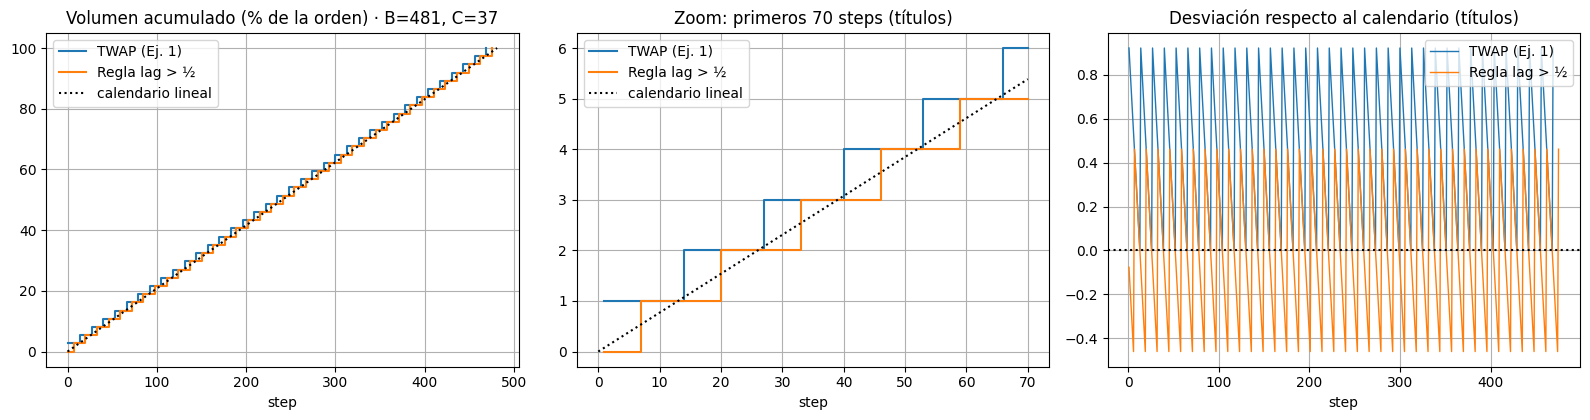

In [9]:
# ➕ Mismo episodio con las dos políticas-calendario frente a la recta del calendario lineal
seed_ep = 10_003
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for name, color in (("TWAP (Ej. 1)", "tab:blue"), ("Regla lag > ½", "tab:orange")):
    np.random.seed(seed_ep)
    s, done = env_pol.reset(), False
    while not done:
        s, r, done, _ = env_pol.step(policies[name](s))
    B, C, n = env_pol.episode_bins, env_pol.vol_care, env_pol.state_pos
    x = np.arange(1, n + 1)
    ejec = np.cumsum(env_pol.vol_hist)
    ax[0].step(x, ejec / C * 100, where="post", color=color, label=name)
    ax[1].step(x[:70], ejec[:70], where="post", color=color, label=name)
    ax[2].plot(x, ejec - C * x / B, color=color, label=name, lw=1)
ax[0].plot([0, B], [0, 100], "k:", label="calendario lineal"); ax[0].set_title(f"Volumen acumulado (% de la orden) · B={B}, C={C}")
ax[1].plot(np.arange(0, 71), C * np.arange(0, 71) / B, "k:", label="calendario lineal"); ax[1].set_title("Zoom: primeros 70 steps (títulos)")
ax[2].axhline(0, color="k", ls=":"); ax[2].set_title("Desviación respecto al calendario (títulos)")
for a_ in ax:
    a_.grid(True); a_.legend(); a_.set_xlabel("step")
plt.tight_layout(); plt.show()

**Demostración por programación dinámica.** El entorno es determinista y su estado relevante es solo `(t, e)` (steps consumidos y títulos comprados), así que se puede calcular la **política óptima exacta** por inducción hacia atrás para unos cuantos `(B, C)` y compararla con la regla `lag > ½`. Se hace con distintos factores de descuento `γ` y **con y sin** la recompensa final de §2.3, para comprobar el punto 7 de la justificación. La última comprobación cruza la DP con el entorno real: el valor óptimo `V(0,0)` con `γ = 1` debe coincidir con el retorno que obtiene la regla en el entorno.

> ➕ **BLOQUE AÑADIDO** — programación dinámica exacta de la recompensa del §2.3 (no existía en el Ejercicio 1).

In [10]:
def solve_dp(B, C, gamma=1.0, done_reward=True):
    """Política óptima exacta (inducción hacia atrás) sobre (t, e). Devuelve (política[t, e], V[t, e])."""
    V = np.zeros((B + 1, C + 1))
    pol = np.zeros((B, C), dtype=int)                  # e == C no existe: el episodio ya terminó
    for t in range(B - 1, -1, -1):
        sched = C * (t + 1) / B
        # recompensa final si la orden se completa en este step: steps sin jugar t+1 .. B-1 (calendario sigue avanzando)
        pen = -np.abs(C - C * np.arange(t + 2, B + 1) / B).sum() if done_reward else 0.0
        for e in range(C):
            q = np.empty(2)
            for a in (0, 1):
                e1 = e + a
                r = -abs(e1 - sched)
                if e1 >= C:                            # orden completada
                    q[a] = r + pen
                elif t + 1 >= B:                       # tiempo agotado
                    q[a] = r
                else:
                    q[a] = r + gamma * V[t + 1, e1]
            pol[t, e] = int(q[1] > q[0])
            V[t, e] = q.max()
    return pol, V


def rule_policy(B, C):
    """Regla lag > 1/2 sobre toda la malla (t, e)."""
    t_idx, e_idx = np.meshgrid(np.arange(B), np.arange(C), indexing="ij")
    return (C * (t_idx + 1) / B - e_idx > 0.5).astype(int), C * (t_idx + 1) / B - e_idx


rows = []
for B, C in [(400, 30), (500, 50), (600, 75)]:
    rule, lag = rule_policy(B, C)
    relevant = np.abs(lag) <= 5                        # estados con |lag| <= 5 órdenes (los que ve la red sin recortar)
    for gamma in (1.0, 0.99, 0.9):
        row = {"B": B, "C": C, "γ": gamma}
        for dr in (False, True):
            pol, _ = solve_dp(B, C, gamma, dr)
            row["con recompensa final" if dr else "sin recompensa final"] = f"{(pol == rule)[relevant].mean() * 100:.1f} %"
        rows.append(row)
display(pd.DataFrame(rows).set_index(["B", "C", "γ"]))

# Cruce con el entorno real: V(0,0) con γ = 1 == retorno de la regla ejecutada en el entorno
env_dp = BestExecutionEnv(dict_["train"], 60)
for seed in range(5):
    np.random.seed(seed)
    s, done = env_dp.reset(), False
    while not done:
        s, r, done, _ = env_dp.step(int(s[2] * env_dp.LAG_CLIP > 0.5))
    _, V = solve_dp(env_dp.episode_bins, env_dp.vol_care, 1.0, True)
    assert np.isclose(V[0, 0], np.sum(env_dp.reward_hist)), (V[0, 0], np.sum(env_dp.reward_hist))
print("✔ DP == entorno: el valor óptimo V(0,0) coincide con el retorno que obtiene la regla lag > ½ en el simulador (5 episodios)")

sin recompensa final con recompensa final
B   C  γ                                             
400 30 1.00               83.7 %              100.0 %
       0.99               86.7 %              100.0 %
       0.90               93.1 %              100.0 %
500 50 1.00               92.4 %              100.0 %
       0.99               93.5 %              100.0 %
       0.90               96.3 %              100.0 %
600 75 1.00               95.9 %              100.0 %
       0.99               96.3 %              100.0 %
       0.90               97.8 %              100.0 %

✔ DP == entorno: el valor óptimo V(0,0) coincide con el retorno que obtiene la regla lag > ½ en el simulador (5 episodios)



**Lectura**

* **Con la recompensa final, la política óptima exacta coincide al 100 % con la regla `lag > ½`**, para los tres tamaños de episodio y para γ = 1, 0.99 y 0.9 (en los estados con |lag| ≤ 5, que son los que ve la red). Es decir: el óptimo de la recompensa **es** el TWAP y no hay ningún atajo que un agente pueda explotar.
* **Sin la recompensa final solo coincide en el 84–98 % de los estados.** El óptimo exacto prefiere comprar los últimos títulos algo antes, porque completar la orden *corta* las penalizaciones del resto del episodio: sería un TWAP que termina antes de tiempo. Esto justifica el punto 7 de §2.3.
* **La DP y el simulador coinciden** (`assert` sobre 5 episodios): el valor óptimo `V(0,0)` con γ = 1 es exactamente el retorno que obtiene la regla en el entorno real, así que la DP está resolviendo *este* entorno y no una versión idealizada.
* **Consecuencia importante:** el diseño es correcto y, si el entrenamiento falla, el fallo será de **optimización** (hiperparámetros) y no de **diseño**. Es lo que ocurre en el siguiente apartado.


### 2.6 Primer entrenamiento, con los hiperparámetros del Ejercicio 1

Con el diseño validado se entrena el Double DQN **con exactamente los hiperparámetros del Ejercicio 1** (γ = 0.99, buffer de 50 000, lote de 64, α = 10⁻³, 32 neuronas, aprender cada 64 steps, 300 episodios). Es el resultado de la Parte 1: qué consigue la nueva recompensa *sin* ajustar nada. El orden de la interacción es el del Ejercicio 1 (véase su §5.0):

```
relleno del buffer con ε = 1  →  por episodio:  reset → act → step → experience → learn (cada learn_after) → update_target (cada update_target_after) → ε ← ε − decay
```

#### Un agente equivalente, pero más rápido

La Parte 2 requiere decenas de entrenamientos. En el `DDQNAgent` original el coste lo dominan dos cosas: cada decisión llama a Keras para evaluar **un solo estado** (~1 ms) y cada `learn()` hace tres inferencias de Keras más `train_on_batch` (~14 ms). `FastDDQNAgent` hereda de `DDQNAgent` y solo cambia **cómo** se calcula, no **qué**:

* `_act_no_explore`: la red es un MLP de 2 capas ocultas, así que la inferencia de un estado se hace en numpy con los pesos (cacheados, y se invalidan tras cada `learn()`).
* `learn()`: mismo muestreo CER, mismo objetivo Double DQN (la *primary* elige la acción, la *target* la evalúa) y misma pérdida MSE con el mismo optimizador Adam; solo se calculan los Q-valores con numpy y el paso de gradiente se compila con `tf.function`.

Se **comprueba numéricamente** contra el original (misma decisión *greedy* en 500 estados; con el mismo batch, misma pérdida y mismos pesos tras el paso de gradiente).

> **Nota sobre la pérdida.** `DDQNAgent.learn()` devuelve lo que devuelve `train_on_batch` de Keras 3, que es una **media acumulada** desde la primera llamada (no se reinician las métricas). El `mse` que se imprimía en el Ejercicio 1 era por tanto una media acumulada, mucho más suave que la pérdida real de cada batch. `FastDDQNAgent` devuelve la pérdida **real** del batch.

> ➕ **BLOQUE AÑADIDO** — `FastDDQNAgent` (subclase de `DDQNAgent`; el original del repositorio no se toca) y su verificación numérica.

In [11]:
import time


class FastDDQNAgent(DDQNAgent):
    """Double DQN idéntico a DDQNAgent, con inferencia en numpy y paso de gradiente compilado (≈ 4× más rápido por learn)."""

    def __init__(self, *args, **kwargs):
        self._w = None                                   # pesos de la red primary cacheados para la inferencia
        super().__init__(*args, **kwargs)
        model, optimizer = self.primary_model, self.primary_model.optimizer

        @tf.function(reduce_retracing=True)
        def _train_step(x, y):                           # mismo MSE y mismo Adam que train_on_batch
            with tf.GradientTape() as tape:
                loss = tf.reduce_mean(tf.square(y - model(x, training=True)))
            grads = tape.gradient(loss, model.trainable_variables)
            optimizer.apply_gradients(zip(grads, model.trainable_variables))
            return loss
        self._train_step = _train_step

    @staticmethod
    def _forward(weights, x):                            # Dense(relu) -> Dense(relu) -> Dense(linear), en numpy
        W1, b1, W2, b2, W3, b3 = weights
        h = np.maximum(x @ W1 + b1, 0)
        h = np.maximum(h @ W2 + b2, 0)
        return h @ W3 + b3

    def _act_no_explore(self, s):
        if self._w is None:
            self._w = self.primary_model.get_weights()
        return int(np.argmax(self._forward(self._w, s)))

    def learn(self):
        batch = self.sample()                            # CER, igual que el original
        s_list = np.array([e[0].tolist() for e in batch], dtype=np.float32)
        s1_list = np.array([e[3].tolist() for e in batch if e[3] is not None], dtype=np.float32)
        w_primary, w_target = self.primary_model.get_weights(), self.target_model.get_weights()
        targets = self._forward(w_primary, s_list)
        qs1 = self._forward(w_primary, s1_list)          # la primary ELIGE la mejor acción siguiente...
        q_target = self._forward(w_target, s1_list)      # ...y la target la EVALÚA (Double DQN)
        k = 0
        for i, (s, a, r, s1) in enumerate(batch):
            if s1 is None:
                targets[i][a] = r
            else:
                targets[i][a] = r + self.gamma * q_target[k, np.argmax(qs1[k])]
                k += 1
        loss = float(self._train_step(s_list, targets.astype(np.float32)))   # pérdida REAL del batch
        self._w = None                                   # los pesos han cambiado: invalidar la caché
        return loss


# --- Verificación numérica contra el DDQNAgent original -------------------------------------
env_t = BestExecutionEnv(dict_["train"], 60)
np.random.seed(0); tf.random.set_seed(0)
ag_ref = DDQNAgent(env_t, gamma=0.95, epsilon=1.0, alpha=1e-3)
ag_fast = FastDDQNAgent(env_t, gamma=0.95, epsilon=1.0, alpha=1e-3)
ag_fast.primary_model.set_weights(ag_ref.primary_model.get_weights())
ag_fast.update_target(); ag_ref.update_target()
s = env_t.reset()
for _ in range(3000):                                    # mismo buffer en los dos agentes
    a = ag_ref.act(s)
    s1, r, d, _ = env_t.step(a)
    ag_ref.experience(s, a, r, s1, d); ag_fast.experience(s, a, r, s1, d)
    s = s1
    if d:
        s = env_t.reset()

S = np.column_stack([np.random.rand(500, 2), np.random.uniform(-1, 1, 500)])
assert all(ag_ref._act_no_explore(x) == ag_fast._act_no_explore(x) for x in S), "decisiones distintas"
np.random.seed(123); loss_ref = ag_ref.learn()           # primera llamada: Keras devuelve la pérdida real del batch
np.random.seed(123); loss_fast = ag_fast.learn()         # mismo batch (misma semilla)
w_ref = np.concatenate([w.ravel() for w in ag_ref.primary_model.get_weights()])
w_fast = np.concatenate([w.ravel() for w in ag_fast.primary_model.get_weights()])
print(f"misma decisión greedy en 500 estados · pérdida original {loss_ref:.6f} vs rápida {loss_fast:.6f} · max|Δpesos| = {np.abs(w_ref - w_fast).max():.1e}")
assert abs(loss_ref - loss_fast) < 1e-4 and np.abs(w_ref - w_fast).max() < 1e-5

t0 = time.perf_counter(); [ag_ref.learn() for _ in range(100)]; t_ref = (time.perf_counter() - t0) * 10
t0 = time.perf_counter(); [ag_fast.learn() for _ in range(100)]; t_fast = (time.perf_counter() - t0) * 10
t0 = time.perf_counter(); [ag_ref._act_no_explore(S[0]) for _ in range(300)]; a_ref = (time.perf_counter() - t0) / 300 * 1e3
t0 = time.perf_counter(); [ag_fast._act_no_explore(S[0]) for _ in range(300)]; a_fast = (time.perf_counter() - t0) / 300 * 1e3
print(f"learn(): {t_ref:.1f} ms → {t_fast:.1f} ms · act(): {a_ref:.2f} ms → {a_fast:.3f} ms")

misma decisión greedy en 500 estados · pérdida original 17.379749 vs rápida 17.379749 · max|Δpesos| = 1.1e-06


learn(): 13.3 ms → 3.5 ms · act(): 2.45 ms → 0.014 ms


#### La función de entrenamiento

`train_agent` es **el bucle del Ejercicio 1 empaquetado** para poder lanzarlo con distintas configuraciones: crea el entorno y el agente, **rellena el buffer** con ε = 1 (acciones aleatorias), y entrena con el orden `act → step → experience → learn → update_target` y ε decreciente (lineal hasta `min_epsilon` en el 80 % de los episodios, como en el Ejercicio 1; el Ejercicio 3 lo cambiará). Registra por episodio las métricas de §2.1 y la pérdida media.

> ➕ **BLOQUE AÑADIDO** — el cuerpo del bucle (`act`, `step`, `experience`, `learn`, `update_target`, decaimiento de ε) es el del Ejercicio 1; lo nuevo es que va dentro de una función con una configuración y que registra más métricas.

In [12]:
DEFAULT_CFG = dict(               # valores por defecto = los del Ejercicio 1
    nepisodes=300, epsilon=1.0, min_epsilon=0.05, gamma=0.99, alpha=1e-3, buffer_size=50_000,
    batch_size=64, hidden_neurons=32, learn_after=64, update_target_mult=10,    # update_target_after = mult * learn_after
    state_mode="schedule", seed=42,
)


def train_agent(cfg, split="train", n_log=25, verbose=True):
    c = {**DEFAULT_CFG, **cfg}
    learn_after = c["learn_after"]
    update_target_after = c["update_target_mult"] * learn_after
    epsilon_decay = (c["epsilon"] - c["min_epsilon"]) / (0.8 * c["nepisodes"])      # lineal hasta min_epsilon en el 80 %
    np.random.seed(c["seed"]); tf.random.set_seed(c["seed"])
    env = BestExecutionEnv(dict_[split], 60, state_mode=c["state_mode"])
    agent = FastDDQNAgent(env, gamma=c["gamma"], epsilon=c["epsilon"], alpha=c["alpha"], batch_size=c["batch_size"],
                          buffer_size=c["buffer_size"], hidden_neurons=c["hidden_neurons"])
    t0 = time.perf_counter()

    # (1) Relleno del buffer. En este punto epsilon es 1 -> actuando random
    s = env.reset()
    for _ in range(c["buffer_size"]):
        a = agent.act(s)
        s1, r, done, _ = env.step(a)
        agent.experience(s, a, r, s1, done)
        s = s1
        if done:
            s = env.reset()

    # (2) Entrenamiento
    agent.set_trainable(True)
    learn_counter, history = 0, []
    for episode in range(c["nepisodes"]):
        s = env.reset()
        step, cum_reward, ep_losses = 0, 0.0, []
        while True:
            a = agent.act(s)                                          # ε-greedy
            s1, r, done, _ = env.step(a)                              # el entorno evalúa la acción
            agent.experience(s, a, r, s1, done)                       # transición al buffer
            learn_counter += 1
            cum_reward += r
            s = s1
            step += 1
            if not learn_counter % learn_after:
                ep_losses.append(agent.learn())                       # un paso de gradiente con un batch del buffer
            if not learn_counter % update_target_after:
                agent.update_target()                                 # primary -> target
            if done:
                agent.epsilon = max(agent.epsilon - epsilon_decay, c["min_epsilon"])
                m = episode_metrics(env)
                m.update(episode=episode, ret=cum_reward, loss=np.mean(ep_losses) if ep_losses else np.nan, epsilon=agent.epsilon)
                history.append(m)
                if verbose and not episode % n_log:
                    h = pd.DataFrame(history[-n_log:])
                    print(f"Episode: {episode}, steps: {h.steps.mean():.0f}, rew: {h.ret.mean():.1f}, "
                          f"exec: {h.exec_frac.mean() * 100:.0f}%, error calendario: {h.mae_pct.mean():.2f}%, "
                          f"loss: {h.loss.mean():.2f}, eps: {agent.epsilon:.2f}")
                break
    return agent, pd.DataFrame(history), {"cfg": c, "seconds": time.perf_counter() - t0}


def evaluate_agent(agent, split="val", n_episodes=N_EVAL, seed0=10_000):
    """Evaluación greedy (sin exploración ni aprendizaje) sobre episodios fijados por semilla."""
    eval_env = BestExecutionEnv(dict_[split], 60, state_mode=agent.env.state_mode)
    agent.set_trainable(False)
    agent.env = eval_env                       # el agente debe consultar el entorno que realmente ejecuta (ver Ejercicio 1)
    return evaluate(eval_env, agent.act, n_episodes=n_episodes, seed0=seed0)


def plot_training(hist, title=""):
    W = 15
    roll = lambda x: pd.Series(x).rolling(W, min_periods=1).mean()
    fig, ax = plt.subplots(2, 2, figsize=(15, 8))
    ax[0, 0].plot(hist.ret, alpha=0.25, color="tab:blue"); ax[0, 0].plot(roll(hist.ret), color="tab:blue")
    ax[0, 0].set_title(f"Retorno por episodio (media móvil {W})")
    ax[0, 1].plot(roll(hist.mae_pct), color="tab:red"); ax[0, 1].set_yscale("log")
    ax[0, 1].axhline(0.5, color="k", ls=":", label="≈ mínimo teórico (1/(4C) ≈ 0.5 %)"); ax[0, 1].legend()
    ax[0, 1].set_title("Error de seguimiento del calendario (% de la orden, log)")
    ax[1, 0].plot(roll(hist.exec_frac) * 100, color="tab:green", label="% de la orden ejecutado")
    ax[1, 0].plot(roll(hist.time_frac) * 100, color="tab:olive", label="% del tiempo usado"); ax[1, 0].legend()
    ax[1, 0].set_title("Volumen ejecutado y tiempo usado (%)")
    ax[1, 1].plot(roll(hist.loss), color="tab:purple", label="pérdida (MSE real del batch)")
    ax[1, 1].set_yscale("log"); ax[1, 1].set_title("Pérdida (izq.) y ε (der.)")
    ax2 = ax[1, 1].twinx(); ax2.plot(hist.epsilon, color="tab:gray", ls="--"); ax2.set_ylim(0, 1)
    for a_ in ax.ravel():
        a_.grid(True); a_.set_xlabel("episodio")
    fig.suptitle(title); plt.tight_layout(); plt.show()


def plot_gallery(env, named_policies, seeds):
    """Para cada semilla (= un episodio distinto): volumen acumulado (% de la orden) y desviación respecto al calendario."""
    fig, ax = plt.subplots(2, len(seeds), figsize=(5.2 * len(seeds), 7), squeeze=False)
    for j, seed in enumerate(seeds):
        for name, (pol, color) in named_policies.items():
            np.random.seed(seed)
            s, done = env.reset(), False
            while not done:
                s, r, done, _ = env.step(pol(s))
            B, C, n = env.episode_bins, env.vol_care, env.state_pos
            x = np.arange(1, n + 1) / B * 100
            ejec = np.cumsum(env.vol_hist)
            ax[0, j].step(x, ejec / C * 100, where="post", color=color, label=name, lw=1.4)
            ax[1, j].plot(x, ejec - C * np.arange(1, n + 1) / B, color=color, label=name, lw=0.9)
        ax[0, j].plot([0, 100], [0, 100], "k:", label="calendario lineal")
        ini = env.episode.index[0]
        ax[0, j].set_title(f"{ini:%Y-%m-%d %H:%M} · B={B}, C={C}", fontsize=10)
        ax[1, j].axhline(0, color="k", ls=":"); ax[1, j].set_xlabel("% del tiempo del episodio")
    ax[0, 0].set_ylabel("% de la orden ejecutado"); ax[1, 0].set_ylabel("desviación (títulos)")
    ax[0, 0].legend(fontsize=8); ax[1, 0].legend(fontsize=8)
    for a_ in ax.ravel():
        a_.grid(True)
    plt.tight_layout(); plt.show()

> ➕ **BLOQUE AÑADIDO** — entrenamiento con la configuración **del Ejercicio 1** (resultado de la Parte 1).

In [13]:
BASELINE_EPISODES = 300
CFG_EJ1 = dict(nepisodes=BASELINE_EPISODES, gamma=0.99, alpha=1e-3, buffer_size=50_000, batch_size=64,
               hidden_neurons=32, learn_after=64, update_target_mult=10)
agent1, hist1, info1 = train_agent(CFG_EJ1)
print(f"\nEntrenamiento completado en {info1['seconds']:.0f} s")

Episode: 0, steps: 538, rew: -1288.1, exec: 91%, error calendario: 5.44%, loss: 617.95, eps: 1.00


Episode: 25, steps: 345, rew: -4228.3, exec: 100%, error calendario: 17.17%, loss: 188.83, eps: 0.90


Episode: 50, steps: 205, rew: -7420.6, exec: 100%, error calendario: 29.50%, loss: 2635.77, eps: 0.80


Episode: 75, steps: 148, rew: -8678.2, exec: 100%, error calendario: 35.70%, loss: 16359.15, eps: 0.70


Episode: 100, steps: 119, rew: -9955.7, exec: 100%, error calendario: 37.54%, loss: 17030.11, eps: 0.60


Episode: 125, steps: 101, rew: -10297.7, exec: 100%, error calendario: 40.12%, loss: 44824.67, eps: 0.50


... (3 outputs left out)

Episode: 225, steps: 131, rew: -9873.9, exec: 100%, error calendario: 34.35%, loss: 95368.48, eps: 0.11


Episode: 250, steps: 447, rew: -2780.1, exec: 100%, error calendario: 11.96%, loss: 105229.93, eps: 0.05


Episode: 275, steps: 504, rew: -3789.4, exec: 96%, error calendario: 15.68%, loss: 165770.52, eps: 0.05



Entrenamiento completado en 46 s


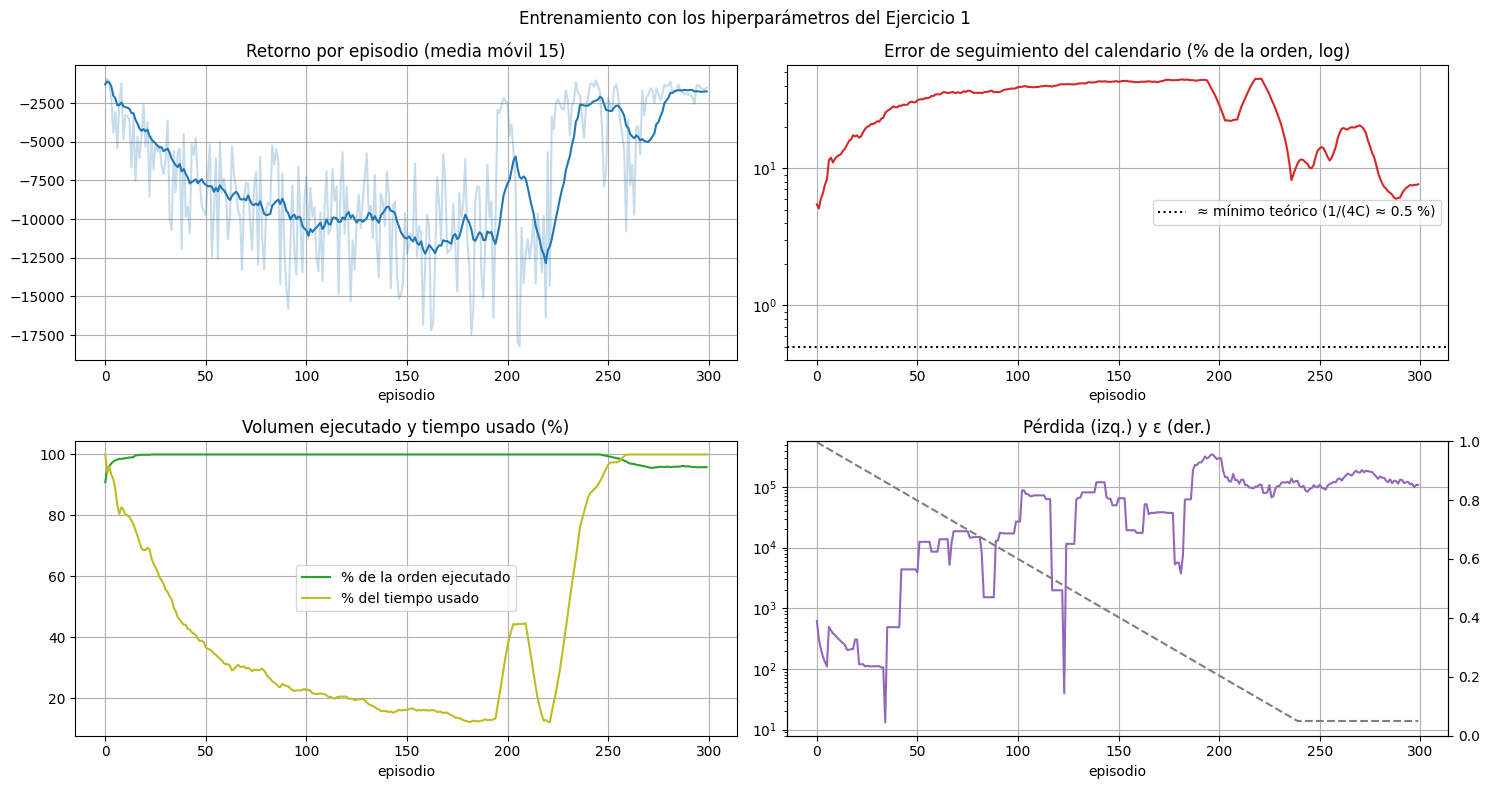

In [14]:
plot_training(hist1, "Entrenamiento con los hiperparámetros del Ejercicio 1")


**Lectura de las curvas.** Con los hiperparámetros del Ejercicio 1 el entrenamiento **no converge**:

* **La pérdida real de cada batch crece de ≈ 10² a ≈ 10⁵** (panel inferior derecho): no está acotada. Los objetivos del Q-learning tienen una escala enorme (con γ = 0.99 el valor acumula ~100 steps de desviaciones, y los episodios que acaban comprando de golpe cobran recompensas finales de miles de títulos) y la red solo recibe **un paso de gradiente cada 64 transiciones**.
* Mientras ε es alto, la política (casi aleatoria) sigue el calendario por azar con un error de ≈ 5 %. Al bajar ε y mandar más la red, **el error sube hasta ≈ 43 %** y el tiempo usado cae al 12 %: la política *greedy* ha degenerado en **comprar de golpe** (se ejecuta el 100 % de la orden en el primer 10–15 % del episodio).
* Cuando ε toca su mínimo (episodio 240) la política recupera algo de sentido (el error baja a ≈ 7 %), pero queda muy lejos del mínimo teórico (≈ 0.5 %).


#### Resultados de la Parte 1 en *train*

Se ejecuta el agente entrenado (*greedy*, sin aprendizaje ni exploración) sobre episodios de *train* y se compara con el TWAP sobre **los mismos episodios**. Primero, un episodio con el gráfico estándar del repositorio (`plot_results`, el mismo tipo de figura que la imagen de referencia del enunciado) y luego la comparación del volumen acumulado frente al calendario en tres episodios distintos.

> ➕ **BLOQUE AÑADIDO** — evaluación y gráficos del primer entrenamiento.

bins             481.000
vol_care          37.000
steps            481.000
exec_frac          0.946
time_frac          1.000
algo_vwap         15.813
mkt_vwap          15.803
slippage_bps       6.471
sum_reward     -1525.000
mae_pct            8.569
max_dev            5.077
gap_cv             0.807


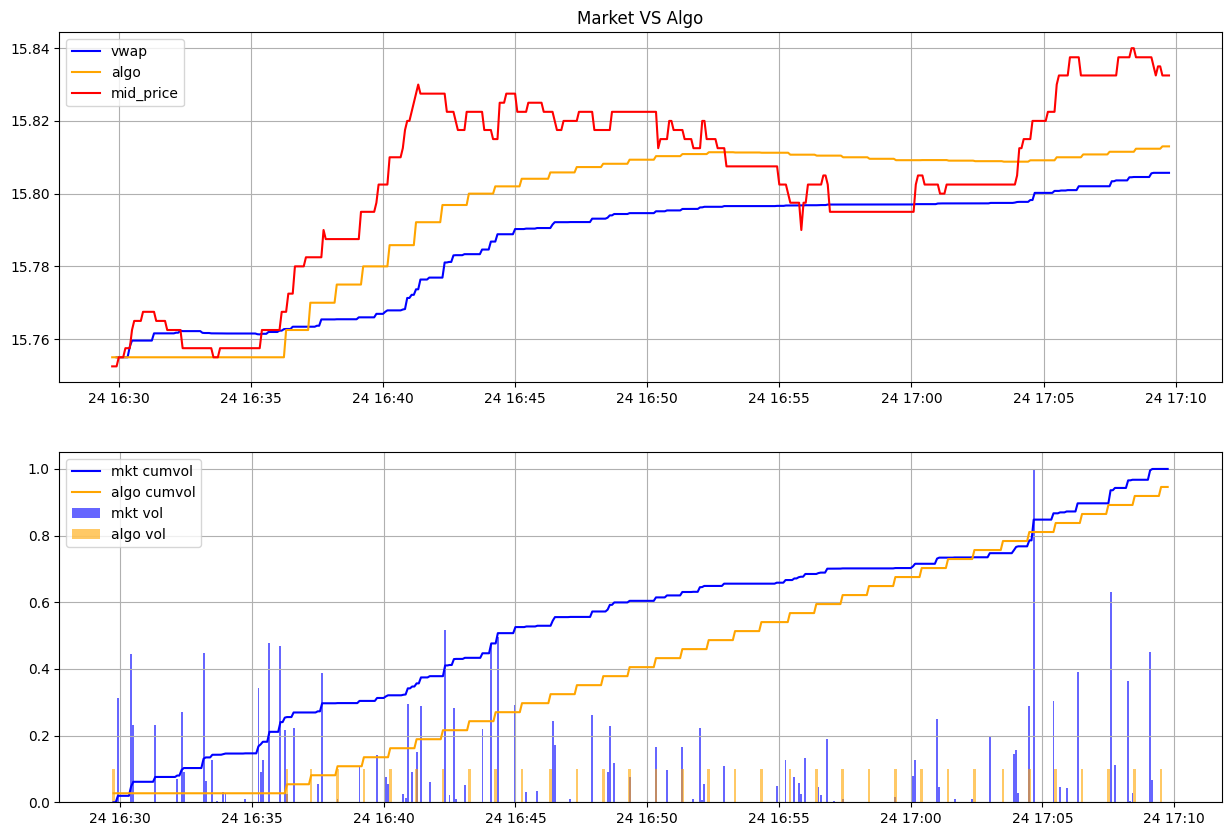

In [15]:
ep_env = BestExecutionEnv(dict_["train"], 60)
agent1.set_trainable(False); agent1.env = ep_env
np.random.seed(10_003)
s, done = ep_env.reset(), False
while not done:
    s, r, done, _ = ep_env.step(agent1.act(s))
print(pd.Series(episode_metrics(ep_env)).round(3).to_string())
plot_results(ep_env); plt.show()

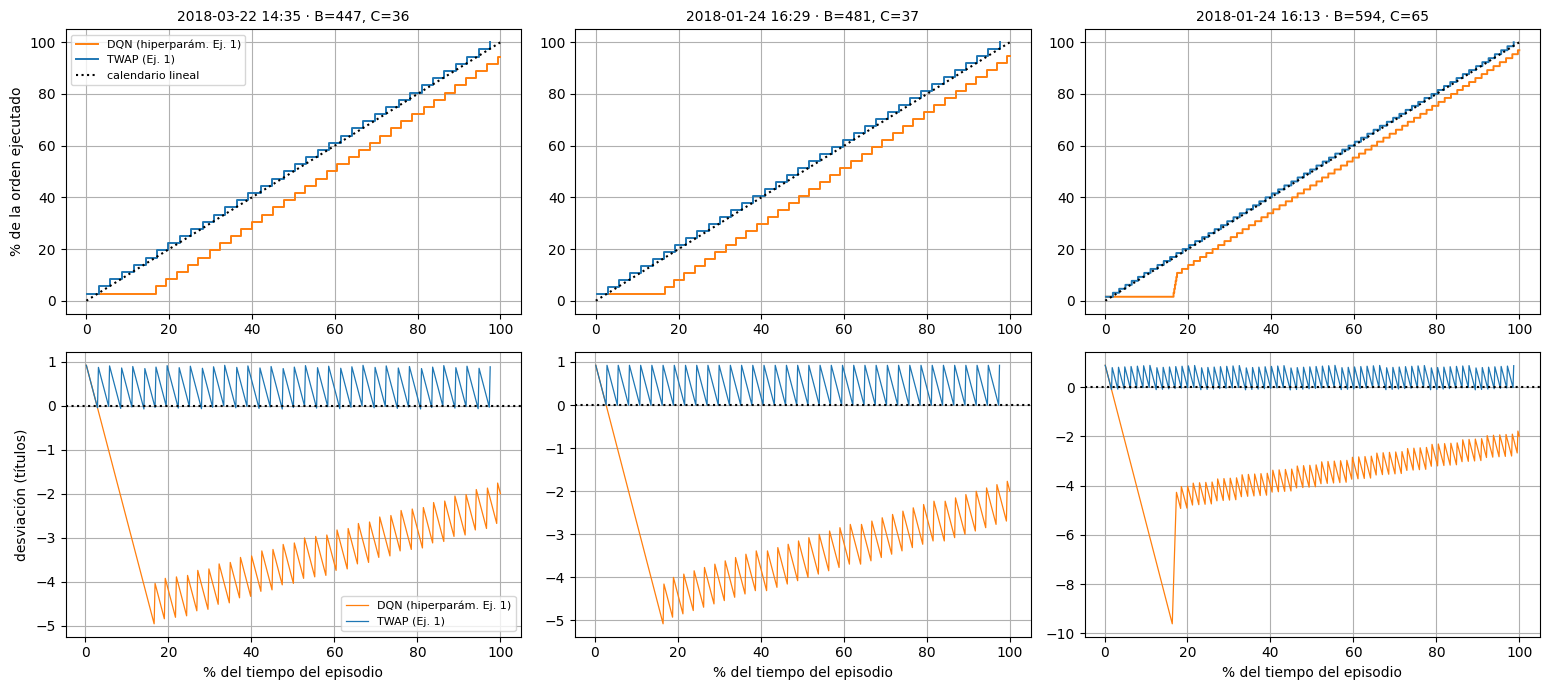

In [16]:
env_g = BestExecutionEnv(dict_["train"], 60)
agent1.env = env_g
plot_gallery(env_g, {"DQN (hiperparám. Ej. 1)": (agent1.act, "tab:orange"), "TWAP (Ej. 1)": (TWAP(env_g).act, "tab:blue")},
             seeds=[10_001, 10_003, 10_007])

In [17]:
res_base = evaluate_agent(agent1, "train")
env_tw = BestExecutionEnv(dict_["train"], 60)
res_tw = evaluate(env_tw, TWAP(env_tw).act, n_episodes=N_EVAL)
display(pd.DataFrame({"DQN (hiperparám. Ej. 1)": summarize(res_base), "TWAP (Ej. 1)": summarize(res_tw)}).round(2))

,DQN (hiperparám. Ej. 1),TWAP (Ej. 1)
C1 · órdenes completas (%),0.00,100.00
volumen ejecutado (% de la orden),95.87,100.00
C2 · tiempo usado (% del episodio),100.00,98.23
C3 · error de seguimiento (% de la orden),6.88,0.86
desvío máximo (títulos),7.24,0.90
C4 · CV de la separación entre compras,1.00,0.04
C5 · slippage vs VWAP (bps) · media,2.20,2.16
retorno (suma de rewards) · media,-1663.29,-203.10



**Lectura de los resultados de la Parte 1 y paso a la Parte 2**

* **El diseño es correcto (§2.5) pero el entrenamiento con los hiperparámetros del Ejercicio 1 no lo aprovecha.** El agente *greedy* no completa **ninguna** orden (C1 = 0 %; ejecuta el 95.9 %), su error de seguimiento es del 6.9 % (frente al 0.86 % del TWAP) y su retorno medio es de ≈ −1 663 (frente a ≈ −203).
* Los gráficos enseñan **cómo** falla: el agente espera durante el primer ≈ 17 % del episodio (el retraso crece hasta 5–10 títulos) y después compra al ritmo correcto —una compra cada `B/C` steps— pero **sin recuperar nunca el retraso acumulado**, así que termina sin completar la orden. Ha aprendido la *forma* (la cadencia) pero no la *regla de corrección*: justo la parte que exige una frontera de decisión precisa.
* **No es un problema de diseño de estado/recompensa**: lo descarta la DP de §2.5. Es un problema de **optimización**: pocos pasos de gradiente por transición (aprender cada 64 steps), valores de escala muy grande (γ = 0.99 más recompensas finales de miles de títulos) y 50 000 transiciones de buffer, muchas de cuando la política era mala.
* **Eso es exactamente lo que dice el enunciado para la Parte 2:** «para asegurarse un correcto entrenamiento es necesario, ahora sí, ajustar la parametría». Se hace en §3.


---
# PARTE 2 · Ajuste y motivación de los hiperparámetros

## 3. Parte 2

La Parte 1 deja un diseño de estado y recompensa **validado como correcto** (§2.5: su óptimo exacto es un TWAP) y un primer entrenamiento que, **con los hiperparámetros del Ejercicio 1, no termina de funcionar** (§2.6). Es exactamente lo que anticipa el enunciado: *«para asegurarse un correcto entrenamiento, es necesario, ahora sí, ajustar la parametría y motivar la decisión»*. En el Ejercicio 1 no tenía sentido ajustar nada porque no había un objetivo claro; ahora sí lo hay y además es medible: los cinco criterios C1–C5 de §2.1.

**Qué se hace en esta parte, en orden:** (§3.1) protocolo de decisión → (§3.2) hipótesis previas sobre cada hiperparámetro → (§3.3) barridos de un hiperparámetro cada vez, evaluados sobre datos de validación → (§3.4) decisión motivada → (§3.5) entrenamiento final → (§3.6) qué ha aprendido la red → (§3.7) gráficos de resultados en *train* → (§3.8) comprobación de que funciona para distintos días, horas, duraciones y tamaños de orden, y de que no es cuestión de suerte (otras semillas).

### 3.1 Cómo se decide: protocolo

* **Qué se optimiza.** Los criterios de §2.1 medidos sobre episodios *greedy*: primero **C1** (completar la orden en el 100 % de los episodios: un algoritmo de ejecución que deja volumen sin ejecutar no sirve) y **C3** (error de seguimiento del calendario; el objetivo es ≈ 0.5 %). C2 y C4 se vigilan. Se considera que una configuración **cumple** si completa el 100 % de las órdenes **y** su error de seguimiento es < 1 % de la orden (el del TWAP del Ejercicio 1 es ≈ 0.9 %).
* **Con qué datos.** Se **entrena** con *train* (2018) y se **selecciona** con *validation* (2019: episodios que el agente no ha visto, con las mismas semillas para todas las configuraciones). *Test* no se toca hasta la comprobación final (§3.8).
* **Cómo se explora.** Barridos de **un hiperparámetro cada vez** alrededor de una configuración de partida, con un presupuesto de 150 episodios por entrenamiento. Es menos eficiente que una búsqueda aleatoria o bayesiana, pero es **interpretable**: cada fila de la tabla responde a «¿qué pasa si cambio solo esto?».
* **Qué se puede concluir de cada barrido.** Los entrenamientos de RL son ruidosos y cada fila usa una sola semilla. Para medir ese ruido se repite la configuración de partida con otras dos semillas, y solo se interpretan diferencias **grandes**: una configuración que cumple frente a otra que no, o diferencias mayores que el ruido entre semillas.
* **Qué no se ajusta.** El tamaño del lote (64, el estándar) y el calendario de ε (lineal hasta 0.05 en el 80 % de los episodios, como en el Ejercicio 1): hacer que ε dependa del aprendizaje es el Ejercicio 3. El número de episodios se decide con las curvas de aprendizaje (§3.5).

### 3.2 Hipótesis previas y configuración de partida

Antes de lanzar los barridos se razona **qué debería pasar** con cada hiperparámetro dada la estructura del problema. La configuración de partida es el resultado de ese razonamiento más una exploración preliminar con presupuesto corto; los barridos de §3.3 comprueban si cada decisión se sostiene.

| Hiperparámetro | Ejercicio 1 | Partida | Hipótesis y motivación | Se prueba |
|---|---|---|---|---|
| `gamma` | 0.99 | **0.95** | La recompensa es **densa y local**: cada step informa de cuánto se desvía el agente y la acción óptima depende solo del retraso actual (§2.3). Un horizonte corto (1/(1−γ) = 20 steps ≈ 2 compras) basta y mantiene los Q-valores en una escala pequeña. Con γ = 0.99 el valor acumula ~100 steps de desviaciones y su rango (de −5 a miles cuando el agente se aleja del calendario) dificulta aprender diferencias de ±1 | 0.5 · 0.9 · 0.99 |
| `learn_after` | 64 | **8** | Con «aprender cada 64 steps» hay **1 paso de gradiente por cada 64 transiciones**: en 300 episodios son unos 2 300 pasos, muy pocos para ajustar una frontera de decisión fina (hay que resolver ½ título). Aprender cada 8 multiplica por 8 los pasos de gradiente por dato; el coste es solo tiempo de cómputo | 16 · 64 |
| `update_target_after` | 10 × `learn_after` | **10 × `learn_after`** (80 steps) | Se mantiene la proporción del original: la red *target* se sincroniza cada 10 aprendizajes | 1× · 100× |
| `buffer_size` | 50 000 | **20 000** | 50 000 transiciones son unos 100 episodios, muchos de cuando la política era mala. Un buffer algo menor mantiene la experiencia más cercana a la política actual; uno demasiado pequeño pierde diversidad (distintos `B`, `C` y retrasos) | 5 000 · 50 000 |
| `alpha` | 1e-3 | **1e-3** | Valor estándar de Adam para una red pequeña. Se espera infraajuste con 1e-4 en este presupuesto e inestabilidad con 1e-2 | 1e-4 · 1e-2 |
| `hidden_neurons` | 32 | **32** | La entrada tiene 3 variables y la política es casi lineal en `lag`: una red pequeña basta, pero con muy pocas neuronas no podría representar la frontera | 8 · 64 |
| estado | `[T, V]` | **`[T, V, lag]`** | §2.2: expresar el retraso en órdenes hijas simplifica el problema | solo `[T, V]` |
| `nepisodes` | 300 | **200** | Se decide con las curvas de aprendizaje (§3.5) | — |

### 3.3 Barridos de hiperparámetros

Cada fila entrena **desde cero** con los pasos de §2.6 (relleno de buffer → bucle de entrenamiento con ε decreciente) y se evalúa *greedy* sobre 40 episodios de **validación**. Los episodios y las semillas son los mismos para todas las filas, así que las diferencias son atribuibles al hiperparámetro y no al azar de los episodios. *Tiempo de ejecución: unos 15 minutos.*

> ➕ **BLOQUE AÑADIDO** — barridos de hiperparámetros con `train_agent` (§2.6), evaluados sobre *validation*.

In [18]:
SWEEP_EPISODES = 150        # presupuesto de cada entrenamiento de los barridos
# Configuración de partida de los barridos (se explica en §3.2). Cada fila cambia UN solo hiperparámetro respecto a ella.
CAND = dict(nepisodes=SWEEP_EPISODES, gamma=0.95, alpha=1e-3, buffer_size=20_000, batch_size=64,
            hidden_neurons=32, learn_after=8, update_target_mult=10)

sweeps = [("candidata", "—", {})]
sweeps += [(f"γ = {g}", "γ (descuento)", dict(gamma=g)) for g in (0.5, 0.9, 0.99)]
sweeps += [(f"aprender cada {k}", "learn_after", dict(learn_after=k)) for k in (16, 64)]
sweeps += [(f"buffer {b:,}".replace(",", " "), "buffer_size", dict(buffer_size=b)) for b in (5_000, 50_000)]
sweeps += [(f"α = {a:g}", "α (learning rate)", dict(alpha=a)) for a in (1e-4, 1e-2)]
sweeps += [(f"{h} neuronas", "hidden_neurons", dict(hidden_neurons=h)) for h in (8, 64)]
sweeps += [(f"target cada {m * 8}", "update_target", dict(update_target_mult=m)) for m in (1, 100)]
sweeps += [("estado básico [T, V]", "estado", dict(state_mode="basic"))]
sweeps += [(f"candidata, semilla {sd}", "semilla", dict(seed=sd)) for sd in (1, 2)]

sweep_rows, sweep_hist = [], {}
for name, group, change in sweeps:
    ag, hist, info = train_agent({**CAND, **change}, verbose=False)
    sm = summarize(evaluate_agent(ag, "val"))                       # selección sobre VALIDATION (30 días de 2019)
    sweep_hist[name] = (group, hist)
    sweep_rows.append({
        "hiperparámetro": group, "valor": name,
        "órdenes completas (%)": sm["C1 · órdenes completas (%)"],
        "volumen ejecutado (%)": sm["volumen ejecutado (% de la orden)"],
        "tiempo usado (%)": sm["C2 · tiempo usado (% del episodio)"],
        "error calendario (%)": sm["C3 · error de seguimiento (% de la orden)"],
        "CV compras": sm["C4 · CV de la separación entre compras"],
        "entrenamiento (s)": info["seconds"],
    })
    r = sweep_rows[-1]
    print(f"{name:<24} completas {r['órdenes completas (%)']:5.1f}% | ejecutado {r['volumen ejecutado (%)']:5.1f}% | tiempo {r['tiempo usado (%)']:5.1f}% | "
          f"error {r['error calendario (%)']:6.2f}% | {r['entrenamiento (s)']:.0f} s")

sweep_df = pd.DataFrame(sweep_rows)
sweep_df["cumple C1–C3"] = (sweep_df["órdenes completas (%)"] == 100) & (sweep_df["error calendario (%)"] < 1.0)
display(sweep_df.round(2).set_index(["hiperparámetro", "valor"]))

candidata                completas 100.0% | ejecutado 100.0% | tiempo  99.2% | error   0.53% | 82 s


γ = 0.5                  completas 100.0% | ejecutado 100.0% | tiempo  99.2% | error   0.53% | 80 s


γ = 0.9                  completas 100.0% | ejecutado 100.0% | tiempo  99.2% | error   0.53% | 72 s


γ = 0.99                 completas   0.0% | ejecutado  97.9% | tiempo 100.0% | error   0.94% | 76 s


aprender cada 16         completas   0.0% | ejecutado  95.9% | tiempo 100.0% | error   0.93% | 50 s


aprender cada 64         completas 100.0% | ejecutado 100.0% | tiempo  10.2% | error  45.84% | 11 s


... (8 outputs left out)

estado básico [T, V]     completas   0.0% | ejecutado  81.4% | tiempo 100.0% | error  21.44% | 63 s


candidata, semilla 1     completas 100.0% | ejecutado 100.0% | tiempo  99.4% | error   0.57% | 68 s


candidata, semilla 2     completas 100.0% | ejecutado 100.0% | tiempo  99.3% | error   0.53% | 70 s


órdenes completas (%)  \
hiperparámetro    valor                                         
—                 candidata                             100.0   
γ (descuento)     γ = 0.5                               100.0   
                  γ = 0.9                               100.0   
                  γ = 0.99                                0.0   
learn_after       aprender cada 16                        0.0   
                  aprender cada 64                      100.0   
buffer_size       buffer 5 000                          100.0   
                  buffer 50 000                           0.0   
α (learning rate) α = 0.0001                            100.0   
                  α = 0.01                              100.0   
hidden_neurons    8 neuronas                              0.0   
                  64 neuronas                           100.0   
update_target     target cada 8                         100.0   
                  target cada 800                       100.0   
estado            estado básico [T, V]                    0.0   
semilla           candidata, semilla 1                  100.0   
                  candidata, semilla 2                  100.0   

                                        volumen ejecutado (%)  \
hiperparámetro    valor                                         
—                 candidata                            100.00   
γ (descuento)     γ = 0.5                              100.00   
                  γ = 0.9                              100.00   
                  γ = 0.99                              97.93   
learn_after       aprender cada 16                      95.87   
                  aprender cada 64                     100.00   
buffer_size       buffer 5 000                         100.00   
                  buffer 50 000                         97.93   
α (learning rate) α = 0.0001                           100.00   
                  α = 0.01                             100.00   
hidden_neurons    8 neuronas                            82.17   
                  64 neuronas                          100.00   
update_target     target cada 8                        100.00   
                  target cada 800                      100.00   
estado            estado básico [T, V]                  81.39   
semilla           candidata, semilla 1                 100.00   
                  candidata, semilla 2                 100.00   

                                        tiempo usado (%)  \
hiperparámetro    valor                                    
—                 candidata                        99.18   
γ (descuento)     γ = 0.5                          99.23   
                  γ = 0.9                          99.22   
                  γ = 0.99                        100.00   
learn_after       aprender cada 16                100.00   
                  aprender cada 64                 10.18   
buffer_size       buffer 5 000                     98.77   
                  buffer 50 000                   100.00   
α (learning rate) α = 0.0001                       10.18   
                  α = 0.01                         99.23   
hidden_neurons    8 neuronas                      100.00   
                  64 neuronas                      99.20   
update_target     target cada 8                    99.23   
                  target cada 800                  99.25   
estado            estado básico [T, V]            100.00   
semilla           candidata, semilla 1             99.39   
                  candidata, semilla 2             99.28   

                                        error calendario (%)  CV compras  \
hiperparámetro    valor                                                    
—                 candidata                             0.53        0.07   
γ (descuento)     γ = 0.5                               0.53        0.08   
                  γ = 0.9                               0.53        0.08   
                  γ = 0.99                     

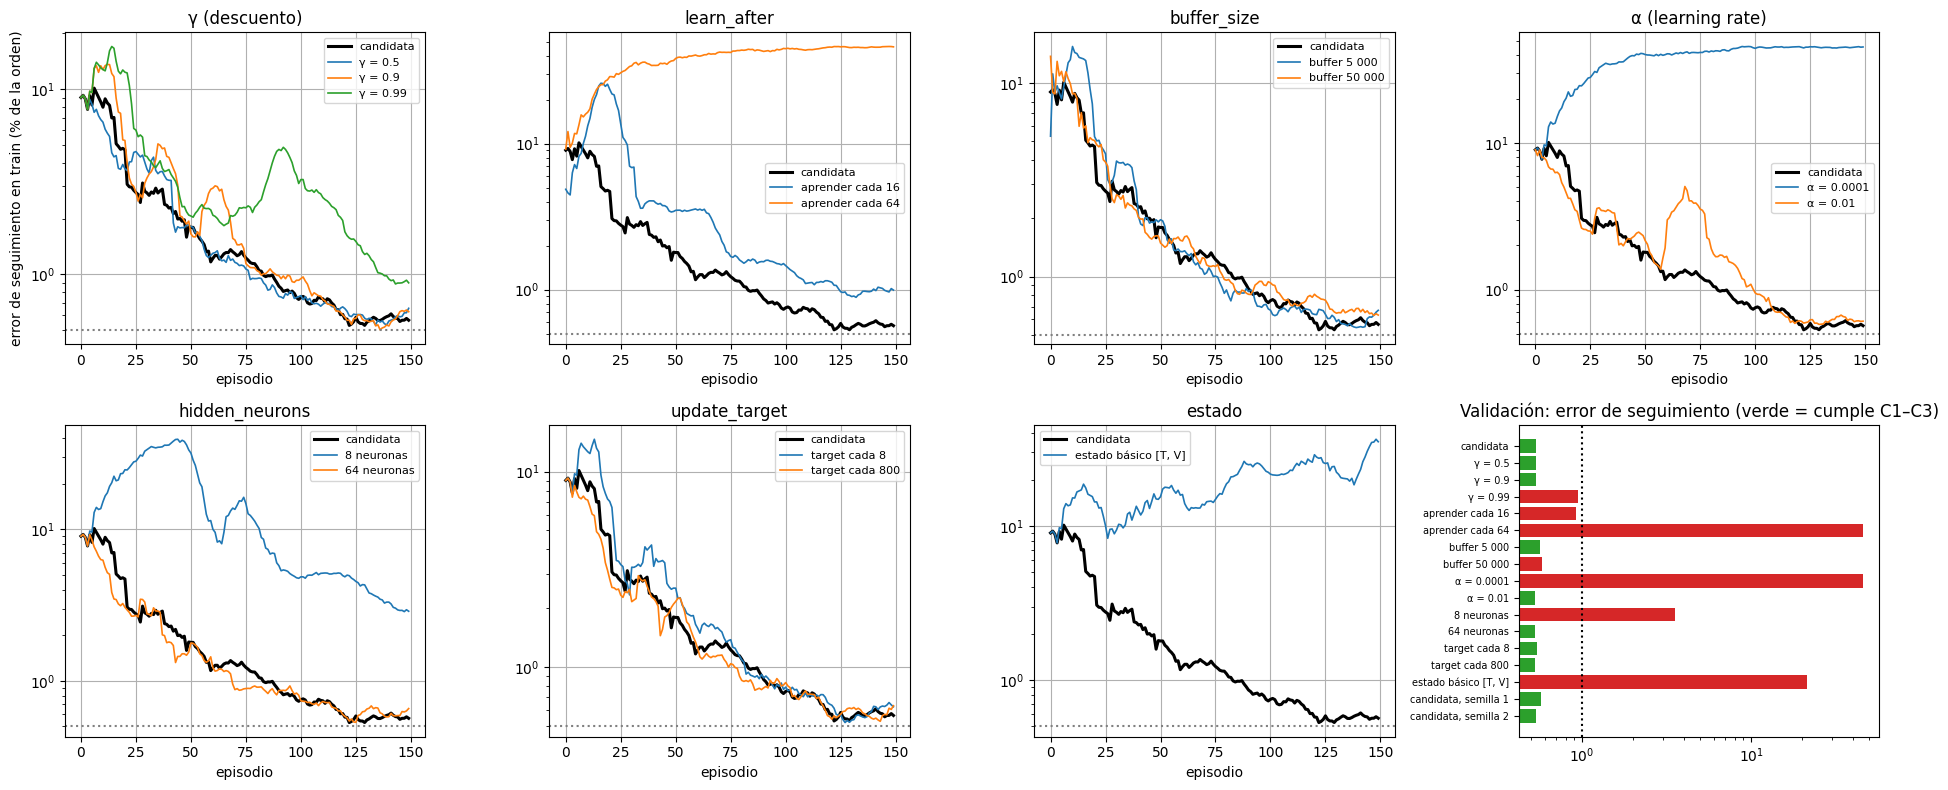

In [19]:
# ➕ Curvas de entrenamiento (error de seguimiento, media móvil de 10 episodios) por hiperparámetro + resultado en validación
groups = ["γ (descuento)", "learn_after", "buffer_size", "α (learning rate)", "hidden_neurons", "update_target", "estado"]
fig, ax = plt.subplots(2, 4, figsize=(19, 8))
cand_err = sweep_hist["candidata"][1].mae_pct.rolling(10, min_periods=1).mean()
for a_, g in zip(ax.ravel(), groups):
    a_.plot(cand_err, color="k", lw=2.2, label="candidata")
    for name, (grp, hist) in sweep_hist.items():
        if grp == g:
            a_.plot(hist.mae_pct.rolling(10, min_periods=1).mean(), label=name, lw=1.2)
    a_.set_yscale("log"); a_.axhline(0.5, color="gray", ls=":"); a_.set_title(g); a_.grid(True)
    a_.set_xlabel("episodio"); a_.legend(fontsize=8)
ax[0, 0].set_ylabel("error de seguimiento en train (% de la orden)")
bars = sweep_df.set_index("valor")["error calendario (%)"]
colors = ["tab:green" if ok else "tab:red" for ok in sweep_df.set_index("valor")["cumple C1–C3"]]
ax[1, 3].barh(range(len(bars)), bars.values, color=colors); ax[1, 3].set_yticks(range(len(bars)))
ax[1, 3].set_yticklabels(bars.index, fontsize=7); ax[1, 3].invert_yaxis(); ax[1, 3].set_xscale("log")
ax[1, 3].axvline(1.0, color="k", ls=":"); ax[1, 3].set_title("Validación: error de seguimiento (verde = cumple C1–C3)")
plt.tight_layout(); plt.show()

**Lectura de los barridos** (tabla, curvas de entrenamiento y barras de validación)

**Cuánto ruido hay.** La configuración de partida repetida con otras dos semillas da un error de 0.53 % / 0.57 % / 0.53 % y cumple los tres criterios las tres veces: el ruido entre semillas es del orden de ±0.02 puntos de error. **Solo se interpretan diferencias mucho mayores que esa.**

**Qué importa y qué no** (de más a menos):

1. **`learn_after` (pasos de gradiente por dato) es lo que más pesa, y confirma la hipótesis.** Aprender cada 8 steps cumple; cada 16 deja de completar las órdenes; cada 64 (el valor del Ejercicio 1) **no aprende nada en 150 episodios**: la política *greedy* compra de golpe (100 % de la orden en el 10 % del tiempo, error del 46 %). Es un problema de pasos de gradiente, no de calidad de los datos.
2. **`gamma`.** 0.5, 0.9 y 0.95 dan exactamente el mismo resultado; **0.99 falla** (0 % de órdenes completas; su curva verde muestra un pico de error del 5 % hacia el episodio 90 antes de recuperarse). Coherente con la hipótesis de la escala de los valores. Y coherente con la DP de §2.5: el óptimo es el mismo para cualquier γ, de modo que γ solo cambia lo **fácil** que es aprenderlo, no la solución.
3. **`alpha`.** 1e-4 infraajusta (el mismo colapso a «comprar de golpe» que `learn_after = 64`); 1e-3 y 1e-2 cumplen, aunque con 1e-2 la curva sufre un pico de inestabilidad hacia el episodio 70.
4. **`hidden_neurons`.** Con 8 neuronas la red no representa bien la frontera (error 3.6 %); 32 y 64 son equivalentes. Se elige la más pequeña que funciona.
5. **`buffer_size`.** 5 000 y 20 000 cumplen; **50 000 no completa ninguna orden** (error 0.58 %). Con un buffer grande la red sigue entrenándose con transiciones de cuando la política era mala y tarda más en aprender los casos poco frecuentes.
6. **`update_target`.** Sincronizar la red *target* cada 8, 80 u 800 steps es indistinguible: no es un hiperparámetro crítico aquí.
7. **Estado.** Con el mismo presupuesto, el agente que solo ve `[time_left, vol_left]` no aprende (error 21 %, ninguna orden completa). No se demuestra que no pudiera aprender con muchísimo más entrenamiento; sí que el retraso en órdenes hijas hace el problema **mucho más barato**, que es lo que se defendió en §2.2.

**Un patrón que merece explicación: «0 % de órdenes completas con un error < 1 %»** (`gamma = 0.99`, `learn_after = 16`, `buffer = 50 000`). Esas configuraciones siguen bien el calendario, pero ejecutan solo el 98 % de la orden (95.9 % con `learn_after = 16`) en todos los episodios: les **falta el último título** (los dos últimos en el caso de `learn_after = 16`). Esa transición es la única que termina por *orden completada* (una de cada ~500) y, por tanto, la que menos datos tiene y la última en aprenderse. Por eso **C1 es el criterio más exigente** y el que distingue una configuración «casi buena» de una buena, y por eso se exige explícitamente.

### 3.4 Decisión motivada

| Hiperparámetro | Valor elegido | Evidencia (§3.3) | Motivación |
|---|---|---|---|
| `gamma` | **0.95** | 0.5, 0.9 y 0.95 equivalentes; 0.99 falla | La recompensa es densa y local, así que basta un horizonte corto. Se elige el valor más alto de los que funcionan con margen respecto al que falla (0.99): conserva un horizonte de ≈ 20 steps (un par de compras), que será necesario en el Ejercicio 4 si el estado incorpora precio y la recompensa mira más allá del siguiente step. Con 0.5 el horizonte es de 2 steps: sirve aquí, pero no es transferible |
| `learn_after` | **8** | 8 cumple; 16 y 64 no | Es el hiperparámetro decisivo: hacen falta muchos pasos de gradiente por transición. Con 8 el error llega al mínimo teórico (0.53 % frente a ≈ 0.5 %). No se probó 4 (duplica el coste de cómputo) porque no hay margen que ganar |
| `update_target_after` | **10 × `learn_after`** (80 steps) | indiferente entre 8 y 800 | Se mantiene la proporción del Ejercicio 1 |
| `buffer_size` | **20 000** | 5 000 y 20 000 cumplen; 50 000 no | Unos 40 episodios de experiencia: suficiente diversidad (distintos `B`, `C` y retrasos) sin arrastrar demasiada experiencia obsoleta |
| `alpha` | **1e-3** | 1e-3 y 1e-2 cumplen; 1e-4 no | De los dos valores que cumplen, el menor: con 1e-2 hay un pico de inestabilidad |
| `hidden_neurons` | **32** | 8 no cumple; 32 y 64 equivalentes | La más pequeña con margen: la política es casi lineal en `lag` |
| `batch_size` | 64 | no se ajusta | Valor estándar |
| ε (`epsilon`, `min_epsilon`, decaimiento) | 1.0 → 0.05, lineal hasta el 80 % | no se ajusta | Igual que en el Ejercicio 1; hacerlo depender del aprendizaje es el Ejercicio 3 |
| `nepisodes` | **200** | curvas de §3.3 | Ver §3.5 |
| estado | **`[T, V, lag]`** | el estado básico no aprende | §2.2 |

**Lo que no se ha explorado:** interacciones entre hiperparámetros (los barridos varían uno cada vez), otras semillas en cada fila (solo en la candidata) y valores intermedios (p. ej. aprender cada 12 steps). Es una decisión razonada con evidencia, no un óptimo global; para este problema, que es pequeño y casi lineal, el margen entre configuraciones que cumplen es pequeño.

### 3.5 Entrenamiento final

Con la configuración decidida en §3.4 se entrena el agente definitivo con los mismos pasos que en §2.6 (relleno del buffer con ε = 1 → `reset / act / step / experience / learn / update_target` con ε decreciente), con la semilla 42 (la del Ejercicio 1) y **200 episodios**. La elección del número de episodios sale de las curvas de los barridos (§3.3): con 150 episodios el error de entrenamiento todavía estaba bajando cuando ε llegó a su mínimo (episodio 120), así que se amplía a 200 (ε mínimo en el 160) para que la curva tenga tiempo de estabilizarse con la política ya casi *greedy*.

> ➕ **BLOQUE AÑADIDO** — entrenamiento final con la configuración elegida (semilla 42, la del Ejercicio 1).

In [20]:
FINAL_EPISODES = 200
CFG_FINAL = {**CAND, "nepisodes": FINAL_EPISODES}
print("Configuración final:", {k: CFG_FINAL[k] for k in ("gamma", "alpha", "buffer_size", "batch_size", "hidden_neurons", "learn_after", "update_target_mult", "nepisodes")})
agent_f, hist_f, info_f = train_agent(CFG_FINAL, n_log=20)
print(f"\nEntrenamiento completado en {info_f['seconds']:.0f} s")

Configuración final: {'gamma': 0.95, 'alpha': 0.001, 'buffer_size': 20000, 'batch_size': 64, 'hidden_neurons': 32, 'learn_after': 8, 'update_target_mult': 10, 'nepisodes': 200}


Episode: 0, steps: 348, rew: -1426.0, exec: 100%, error calendario: 9.01%, loss: 21.67, eps: 0.99


Episode: 20, steps: 468, rew: -1896.6, exec: 98%, error calendario: 6.84%, loss: 152.85, eps: 0.88


Episode: 40, steps: 491, rew: -870.8, exec: 99%, error calendario: 3.52%, loss: 126.38, eps: 0.76


Episode: 60, steps: 504, rew: -541.3, exec: 98%, error calendario: 2.09%, loss: 67.86, eps: 0.64


Episode: 80, steps: 514, rew: -366.8, exec: 98%, error calendario: 1.50%, loss: 0.55, eps: 0.52


... (2 outputs left out)

Episode: 140, steps: 496, rew: -172.9, exec: 100%, error calendario: 0.71%, loss: 0.06, eps: 0.16


Episode: 160, steps: 484, rew: -148.1, exec: 100%, error calendario: 0.62%, loss: 0.03, eps: 0.05


Episode: 180, steps: 507, rew: -138.3, exec: 100%, error calendario: 0.55%, loss: 0.03, eps: 0.05



Entrenamiento completado en 94 s


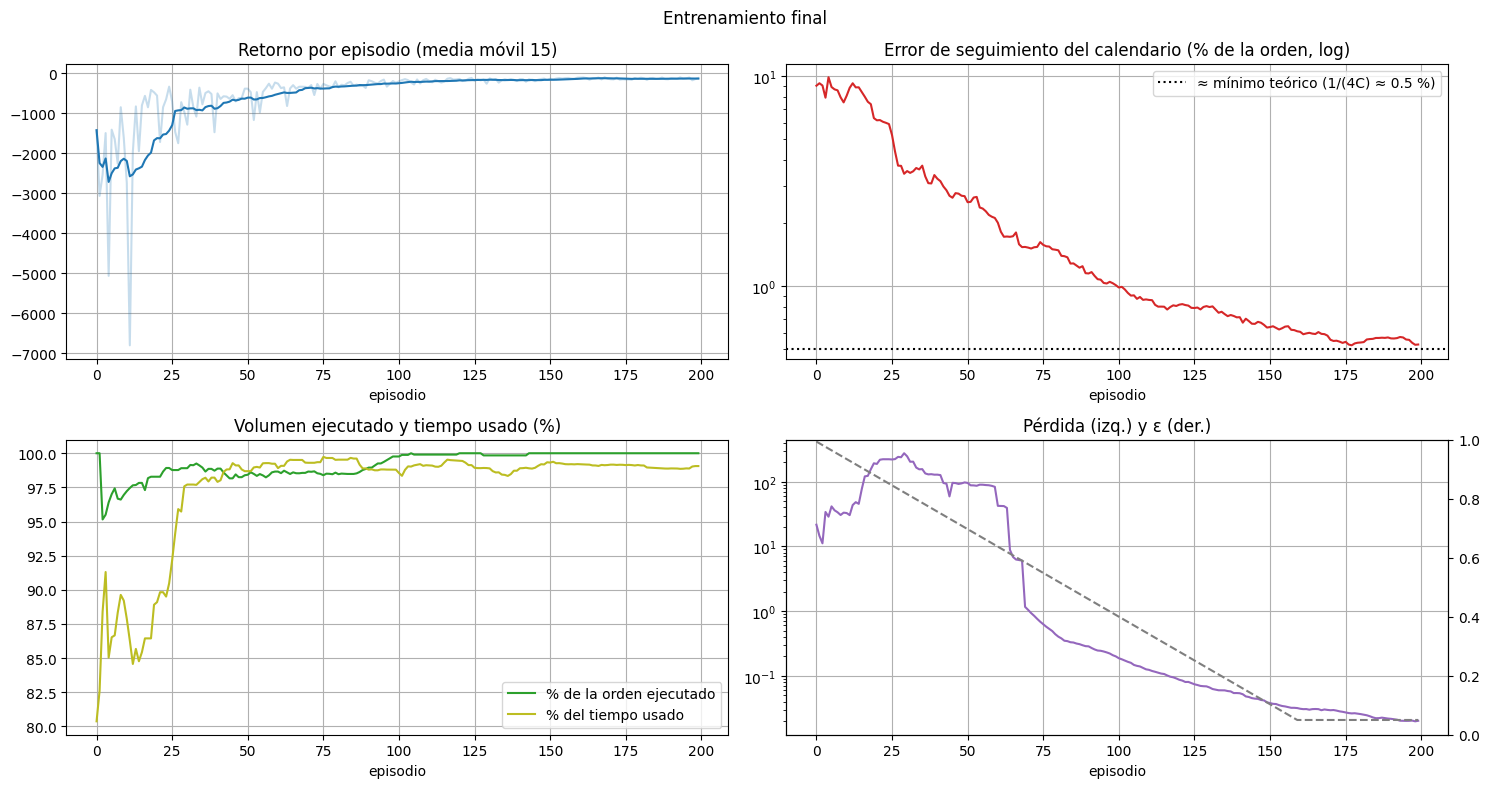

In [21]:
plot_training(hist_f, "Entrenamiento final")

**Lectura de las curvas del entrenamiento final**

* El **retorno** pasa de ≈ −1 400 a ≈ −130 (con la exploración residual de ε = 0.05). En la evaluación *greedy* de §3.8 es de ≈ −127.6, frente a ≈ −123.7 de la regla óptima en los mismos episodios: a un ≈ 3 % del óptimo.
* El **error de seguimiento** baja de ≈ 9 % a ≈ 0.5 %, el mínimo teórico (línea punteada), y se estabiliza hacia el episodio 175, unos 15 episodios después de que ε llegue a su mínimo: 200 episodios son suficientes y dejan algo de margen.
* El **volumen ejecutado** llega al 100 % hacia el episodio 100 y el **tiempo usado** se estabiliza en ≈ 99 %.
* La **pérdida real del batch** (log) sube a ≈ 300 durante los primeros 60 episodios, mientras la red aprende la escala de los valores, y cae a ≈ 0.02: **sin divergencia**, a diferencia del primer entrenamiento (§2.6), donde crecía hasta 10⁵.
* Coste: ≈ 100 s en CPU (con el `FastDDQNAgent`).

### 3.6 Qué ha aprendido la red: política frente a frontera teórica

El mejor test de que la red no ha memorizado algo raro es compararla con la **solución exacta** que se calculó en §2.5. Para tres tamaños de episodio `(B, C)` representativos se evalúa la política de la red sobre **todos** los estados `(t, e)` posibles, tal y como los vería el agente (con sus tres variables), y se dibuja dónde compra y dónde espera. La frontera teórica (línea roja discontinua) es `e = C·(t+1)/B − ½`: por debajo, el agente va más de media orden por detrás del calendario y debe comprar.

> ➕ **BLOQUE AÑADIDO** — mapa de la política aprendida frente a la frontera teórica del TWAP (no existía en el Ejercicio 1).

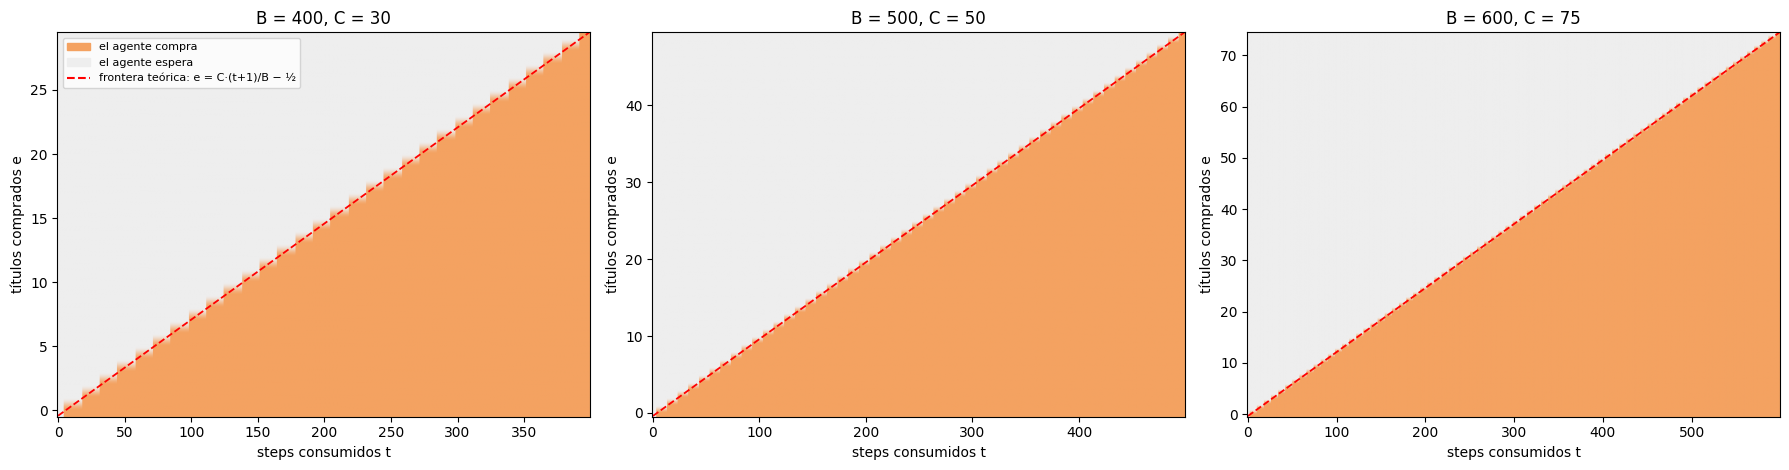

,estados,|lag| ≤ 1.5,|lag| ≤ 5,todos los estados
B,C,,,
400,30,97.4,99.2,99.8
500,50,96.7,99.0,99.8
600,75,96.0,98.7,99.8


In [22]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

probe = BestExecutionEnv(dict_["train"], 60)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
rows = []
for k, (B, C) in enumerate([(400, 30), (500, 50), (600, 75)]):
    probe.episode_bins, probe.vol_care = B, C
    obs = []
    for t in range(B):                                   # todos los estados (t, e) del episodio, tal y como los vería la red
        probe.state_pos = t
        for e in range(C):
            probe.exec_vol = e
            obs.append(probe.observation_builder())
    Q = agent_f.getQs(np.array(obs, dtype=np.float32), agent_f.primary_model)
    learned = (Q[:, 1] > Q[:, 0]).reshape(B, C)
    rule, lag = rule_policy(B, C)
    for nombre, mask in (("todos los estados", np.ones_like(rule, bool)), ("|lag| ≤ 5", np.abs(lag) <= 5), ("|lag| ≤ 1.5", np.abs(lag) <= 1.5)):
        rows.append({"B": B, "C": C, "estados": nombre, "coincidencia con la regla lag > ½ (%)": (learned == rule)[mask].mean() * 100})
    ax[k].imshow(learned.T, origin="lower", aspect="auto", extent=[-0.5, B - 0.5, -0.5, C - 0.5], cmap=ListedColormap(["#eeeeee", "#f4a261"]), vmin=0, vmax=1)
    ax[k].plot(np.arange(B), C * (np.arange(B) + 1) / B - 0.5, "r--", lw=1.3)
    ax[k].set_title(f"B = {B}, C = {C}"); ax[k].set_xlabel("steps consumidos t"); ax[k].set_ylabel("títulos comprados e")
ax[0].legend(handles=[Patch(color="#f4a261", label="el agente compra"), Patch(color="#eeeeee", label="el agente espera"),
                      plt.Line2D([0], [0], color="r", ls="--", label="frontera teórica: e = C·(t+1)/B − ½")], loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).pivot_table(index=["B", "C"], columns="estados", values="coincidencia con la regla lag > ½ (%)")[["|lag| ≤ 1.5", "|lag| ≤ 5", "todos los estados"]].round(1))

**Lectura.** La región naranja (el agente compra) está **exactamente por debajo de la frontera teórica** y la gris (espera) por encima, para los tres tamaños de episodio. La red coincide con la regla `lag > ½` en el **99.8 %** de **todos** los estados `(t, e)` y en el 98.7–99.2 % de los que ve de verdad (|lag| ≤ 5). Las discrepancias (96–97 % en |lag| ≤ 1.5) son píxeles de borde: casos en los que la red adelanta o retrasa la compra un step respecto a la regla, sin consecuencias en el calendario (de ahí el CV de las compras ligeramente mayor que el de un TWAP exacto, §3.8). Es decir, la red **no ha aprendido «algo parecido» a un TWAP: ha aprendido la regla de decisión del TWAP**, para cualquier `B` y `C`, con una sola frontera, tal y como se buscaba al expresar el retraso en órdenes hijas.

### 3.7 Resultados en *train*: imágenes

Son las imágenes que pide el enunciado («basta con enseñar algunas imágenes correctas en el conjunto de *train*»). Se ejecuta el agente final (*greedy*) sobre tres episodios distintos de *train*, cada uno con otro día, otra hora de inicio, otra duración y otro tamaño de orden. Es la misma figura que la de referencia del enunciado (§2.1): **arriba**, VWAP del mercado (azul), VWAP del algoritmo (naranja) y *mid price* (rojo); **abajo**, volumen acumulado del mercado (azul) y del algoritmo (naranja) y, en barras, el volumen negociado en cada bin por el mercado y las compras del algoritmo.

> ➕ **BLOQUE AÑADIDO** — gráficos de resultados en *train* con el agente final.

seed 10001: 2018-03-22 14:35 · B = 447, C = 36 · ejecutado 100% en 98.7% del tiempo · error de calendario 0.72% · CV compras 0.072


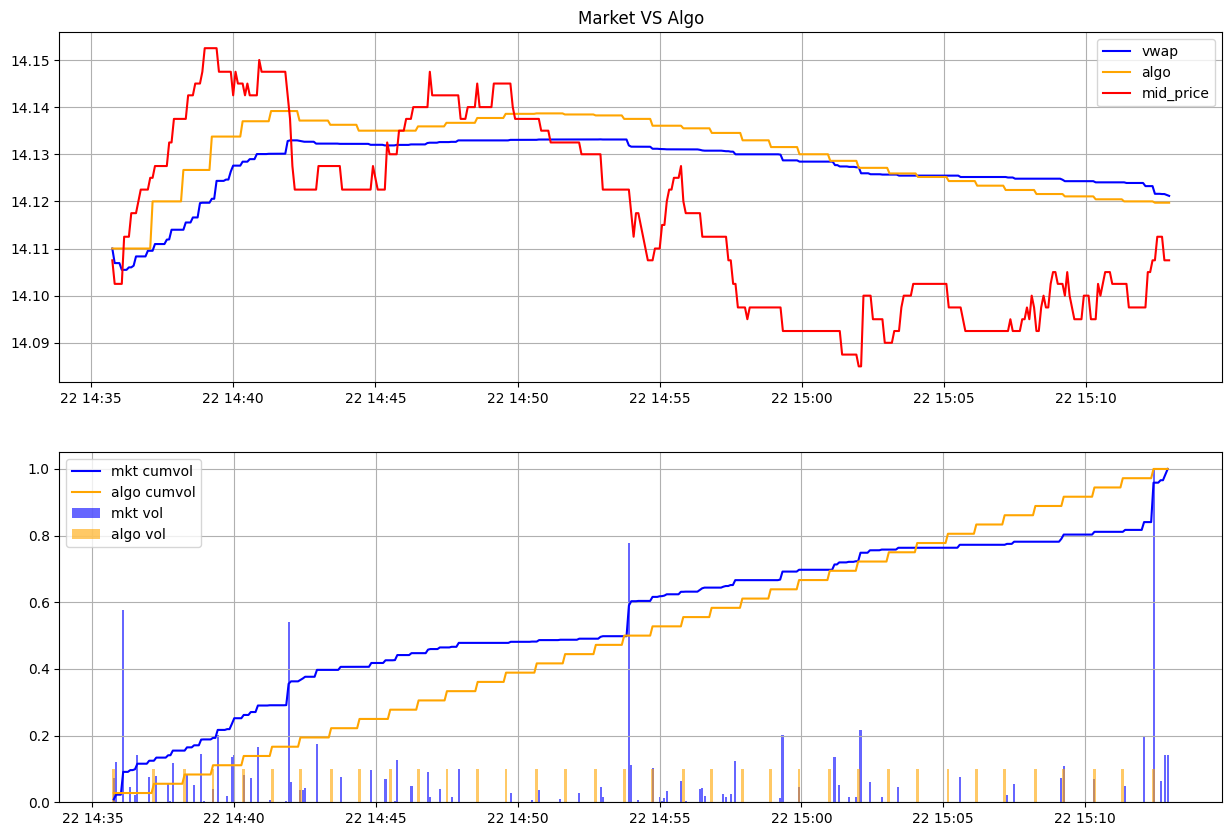

seed 10003: 2018-01-24 16:29 · B = 481, C = 37 · ejecutado 100% en 98.5% del tiempo · error de calendario 0.70% · CV compras 0.063


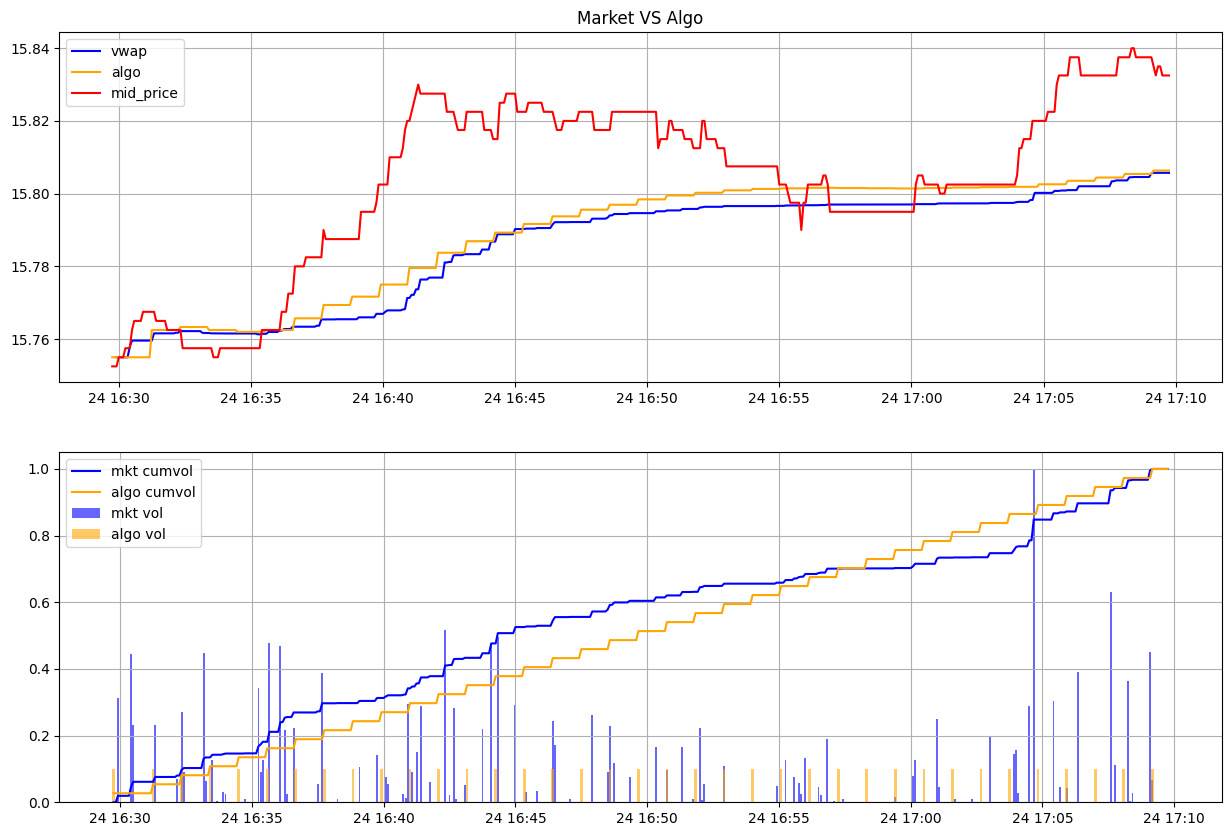

seed 10007: 2018-01-24 16:13 · B = 594, C = 65 · ejecutado 100% en 99.2% del tiempo · error de calendario 0.39% · CV compras 0.063


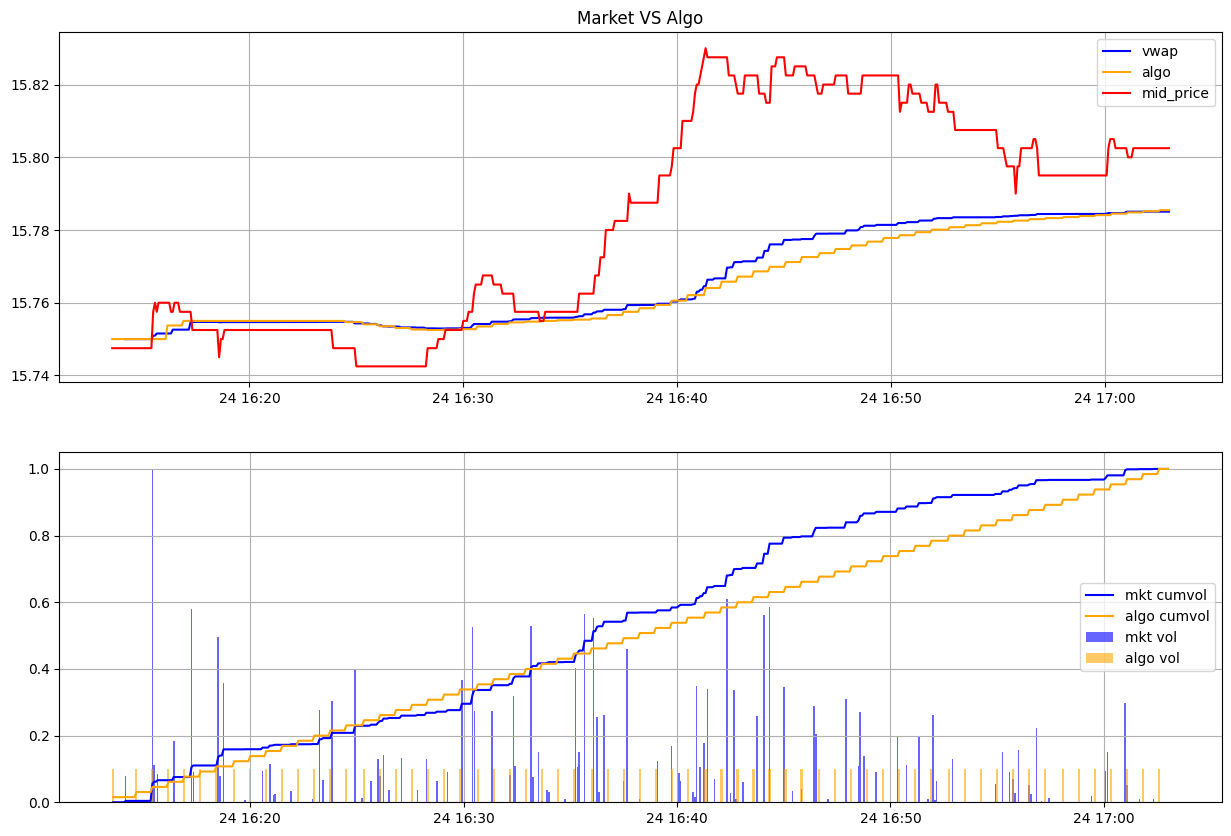

In [23]:
img_env = BestExecutionEnv(dict_["train"], 60)
agent_f.set_trainable(False); agent_f.env = img_env
for seed in (10_001, 10_003, 10_007):                    # tres episodios distintos: día, hora, duración y tamaño de la orden
    np.random.seed(seed)
    s, done = img_env.reset(), False
    while not done:
        s, r, done, _ = img_env.step(agent_f.act(s))
    m = episode_metrics(img_env)
    print(f"seed {seed}: {img_env.episode.index[0]:%Y-%m-%d %H:%M} · B = {m['bins']}, C = {m['vol_care']} · "
          f"ejecutado {m['exec_frac'] * 100:.0f}% en {m['time_frac'] * 100:.1f}% del tiempo · error de calendario {m['mae_pct']:.2f}% · "
          f"CV compras {m['gap_cv']:.3f}")
    plot_results(img_env); plt.show()

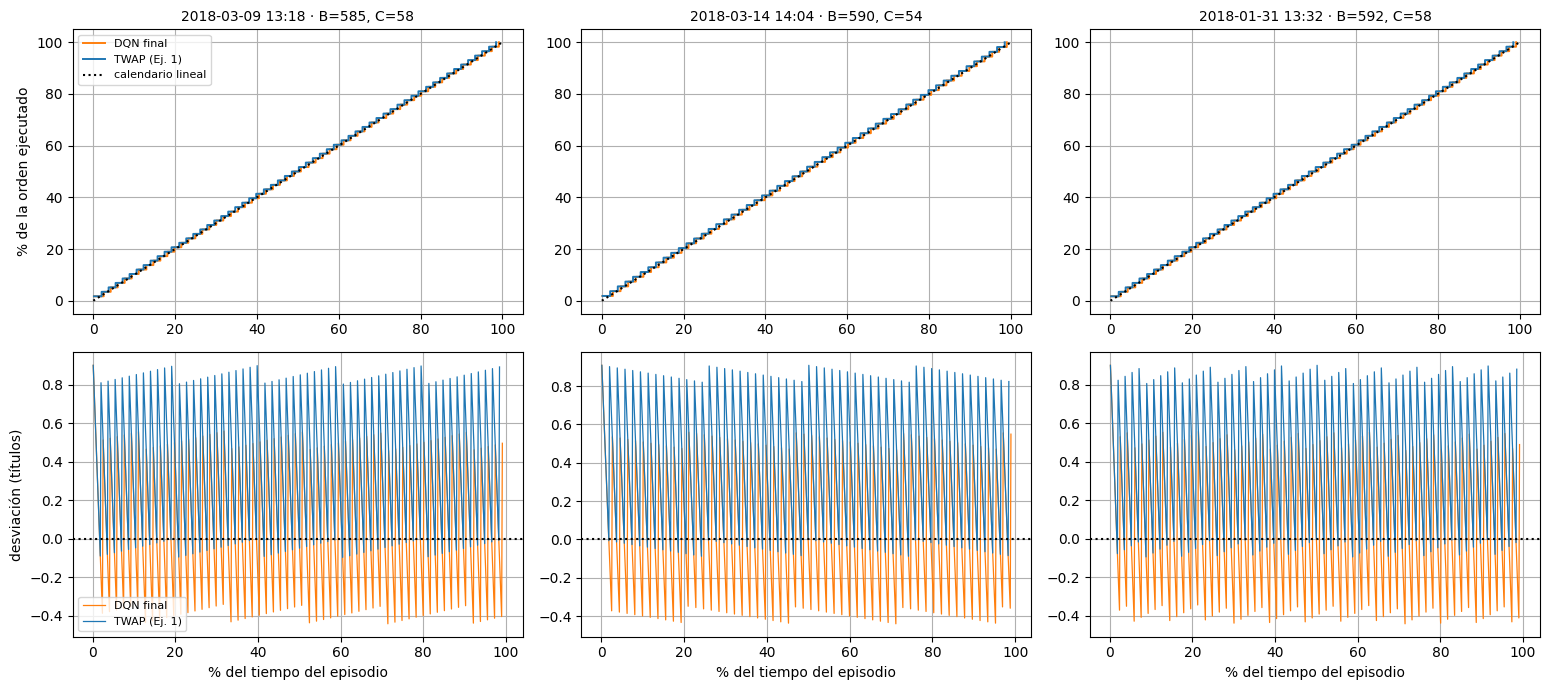

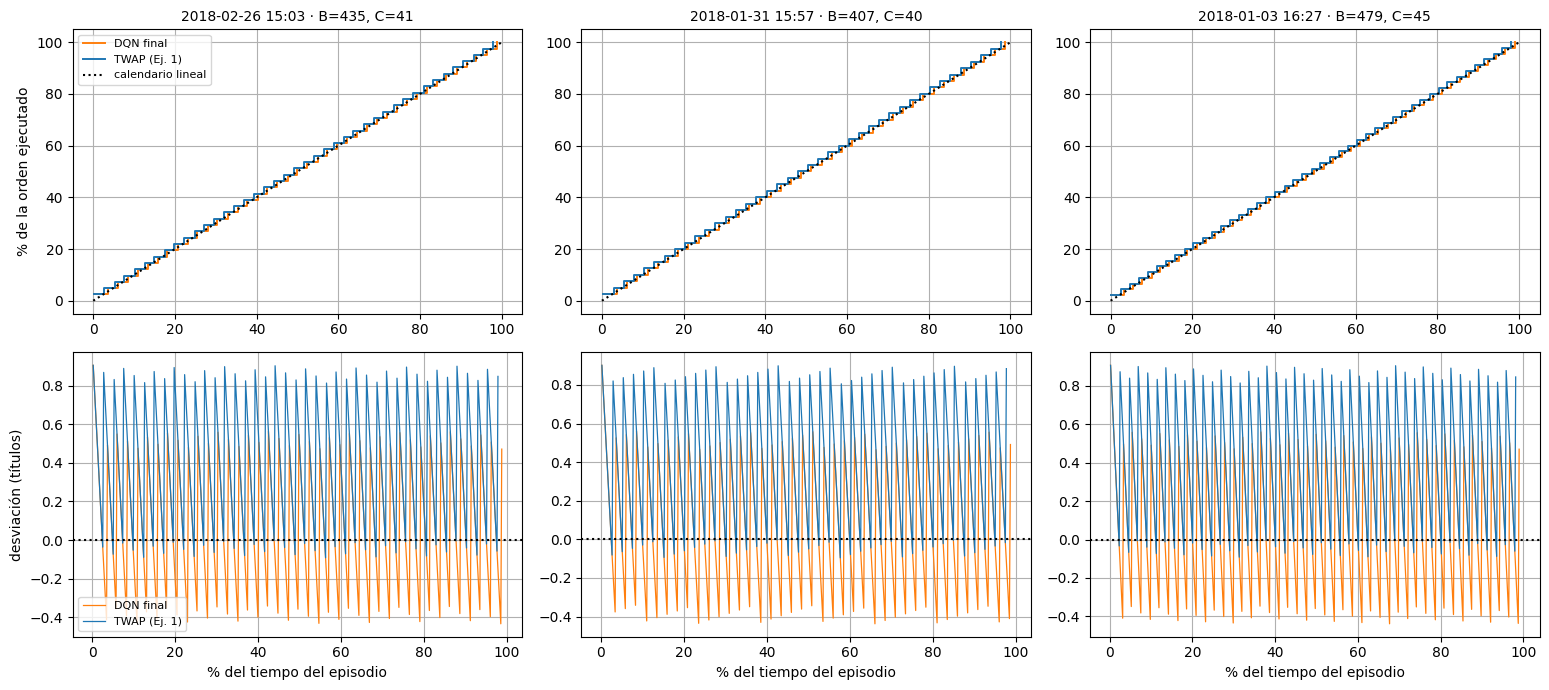

In [24]:
# ➕ Comparación con el TWAP y con el calendario lineal en seis episodios distintos de train
env_g2 = BestExecutionEnv(dict_["train"], 60)
agent_f.env = env_g2
pols = {"DQN final": (agent_f.act, "tab:orange"), "TWAP (Ej. 1)": (TWAP(env_g2).act, "tab:blue")}
plot_gallery(env_g2, pols, seeds=[20_002, 20_005, 20_011])
plot_gallery(env_g2, pols, seeds=[20_017, 20_023, 20_031])

**Lectura de las imágenes**

* **Figuras `plot_results`** (misma figura que la de referencia del enunciado). En el panel inferior, el volumen acumulado del algoritmo (naranja) es **una escalera regular de 0 % a 100 %** que termina justo al final del episodio, mientras que el del mercado (azul) avanza a saltos —el volumen está concentrado en unos pocos *prints*: ≈ 65 % en el 1 % de los bins (§1.3)—. El algoritmo **no reacciona al mercado**: compra a su ritmo con independencia de cuándo negocia el mercado, que es la propiedad C5. En el panel superior, el VWAP del algoritmo (naranja) acompaña al del mercado (azul) sin intentar batirlo.
* Las líneas impresas dan los criterios de cada episodio: 100 % de la orden en el 98.5–99.2 % del tiempo y error de calendario de 0.4–0.7 % (más bajo cuanto mayor es `C`, como se verá en §3.8), con `B` entre 447 y 594 y `C` entre 36 y 65.
* **Galerías** (seis episodios distintos: otro día, otra hora, otra duración y otro tamaño de orden). Arriba, el volumen acumulado del agente y el del TWAP se confunden con el calendario lineal. Abajo, la **desviación** respecto al calendario: la del TWAP del Ejercicio 1 es un diente de sierra entre 0 y +0.9 títulos (siempre por delante); la del agente oscila entre −0.45 y +0.5, **centrada en el calendario**, como la regla óptima. Es una réplica con un comportamiento incluso más fiel al calendario lineal que el TWAP del que parte la comparación.

### 3.8 Requisito del enunciado: distintos días, momentos, duraciones y tamaños de orden

*«El algoritmo debe funcionar para distintos días, momentos temporales, duración del episodio y tamaño de la orden care.»* El entorno sortea los cuatro en cada `reset()`. Para comprobar que el agente funciona **en todos ellos** y no solo de media:

1. Se evalúa el agente *greedy* sobre **200 episodios de *train*, 100 de *validation* y 100 de *test*** (sin exploración ni aprendizaje) junto con el TWAP del Ejercicio 1 y la regla `lag > ½`, **sobre los mismos episodios**.
2. Se dibuja el error de seguimiento en función de `C` y de `B`: si la política generaliza, el error debe seguir la curva teórica `1/(4C)` y no depender de la duración.
3. Se compara con el TWAP episodio a episodio (diferencias pareadas de *slippage* y de error).

> ➕ **BLOQUE AÑADIDO** — evaluación a gran escala (cientos de episodios) y comprobación por tamaño y duración.

In [25]:
N_BIG = {"train": 200, "val": 100, "test": 100}
final_res = {}
for split, n in N_BIG.items():
    env_s = BestExecutionEnv(dict_[split], 60)
    twap_s = TWAP(env_s)
    final_res[split] = {
        "DQN final": evaluate_agent(agent_f, split, n_episodes=n, seed0=30_000),
        "TWAP (Ej. 1)": evaluate(env_s, twap_s.act, n_episodes=n, seed0=30_000),
        "Regla lag > ½": evaluate(env_s, lambda s, env_s=env_s: int(s[2] * env_s.LAG_CLIP > 0.5), n_episodes=n, seed0=30_000),
    }
    print(f"{split}: {n} episodios · {final_res[split]['DQN final'].bins.min()}–{final_res[split]['DQN final'].bins.max()} bins · "
          f"{final_res[split]['DQN final'].vol_care.min()}–{final_res[split]['DQN final'].vol_care.max()} títulos")
    display(pd.DataFrame({name: summarize(df) for name, df in final_res[split].items()}).round(2))

train: 200 episodios · 401–595 bins · 32–72 títulos


,DQN final,TWAP (Ej. 1),Regla lag > ½
C1 · órdenes completas (%),100.00,100.00,100.00
volumen ejecutado (% de la orden),100.00,100.00,100.00
C2 · tiempo usado (% del episodio),98.95,98.22,99.05
C3 · error de seguimiento (% de la orden),0.54,0.86,0.52
desvío máximo (títulos),0.90,0.90,0.50
C4 · CV de la separación entre compras,0.07,0.04,0.04
C5 · slippage vs VWAP (bps) · media,2.76,2.77,2.78
retorno (suma de rewards) · media,-127.55,-204.01,-123.73


val: 100 episodios · 401–595 bins · 33–71 títulos


,DQN final,TWAP (Ej. 1),Regla lag > ½
C1 · órdenes completas (%),100.00,100.00,100.00
volumen ejecutado (% de la orden),100.00,100.00,100.00
C2 · tiempo usado (% del episodio),98.94,98.20,99.05
C3 · error de seguimiento (% de la orden),0.54,0.87,0.53
desvío máximo (títulos),0.90,0.90,0.50
C4 · CV de la separación entre compras,0.07,0.04,0.04
C5 · slippage vs VWAP (bps) · media,1.94,1.83,1.95
retorno (suma de rewards) · media,-127.85,-204.96,-123.95


test: 100 episodios · 401–595 bins · 33–71 títulos


,DQN final,TWAP (Ej. 1),Regla lag > ½
C1 · órdenes completas (%),100.00,100.00,100.00
volumen ejecutado (% de la orden),100.00,100.00,100.00
C2 · tiempo usado (% del episodio),98.94,98.20,99.05
C3 · error de seguimiento (% de la orden),0.54,0.87,0.53
desvío máximo (títulos),0.90,0.90,0.50
C4 · CV de la separación entre compras,0.07,0.04,0.04
C5 · slippage vs VWAP (bps) · media,1.45,1.46,1.47
retorno (suma de rewards) · media,-127.85,-204.96,-123.95


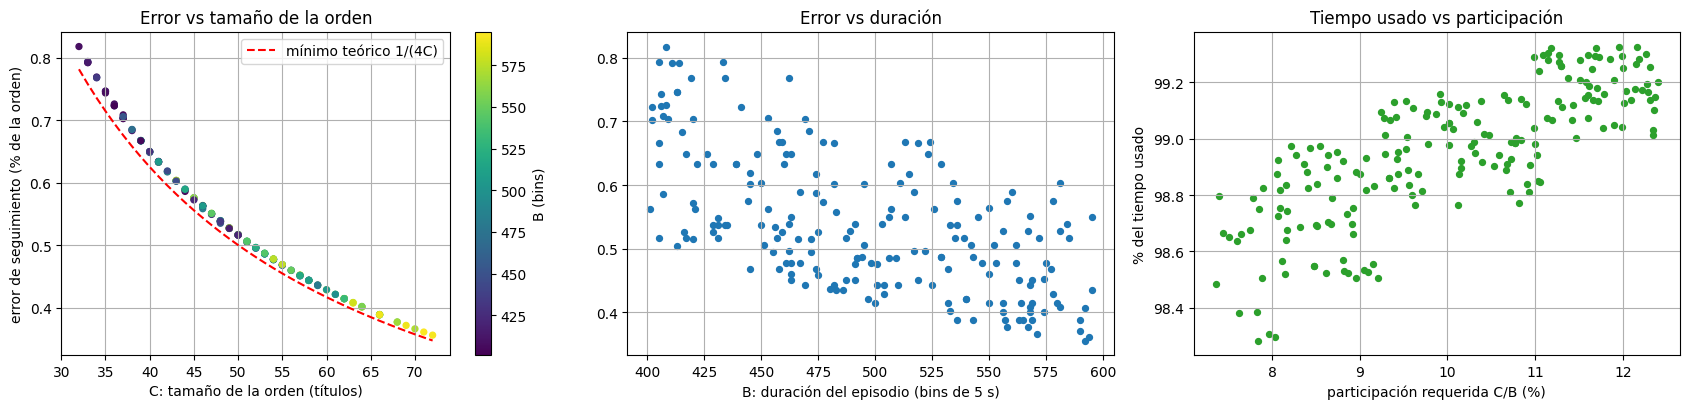

,media,error estándar,episodios
slippage DQN − TWAP (bps),-0.012,0.034,200
error DQN − TWAP (% de la orden),-0.326,0.006,200


In [26]:
# ➕ ¿Depende el error del tamaño de la orden o de la duración del episodio? (DQN final, 200 episodios de train)
d = final_res["train"]["DQN final"]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
sc = ax[0].scatter(d.vol_care, d.mae_pct, c=d.bins, cmap="viridis", s=18); plt.colorbar(sc, ax=ax[0], label="B (bins)")
ax[0].set_xlabel("C: tamaño de la orden (títulos)"); ax[0].set_ylabel("error de seguimiento (% de la orden)"); ax[0].set_title("Error vs tamaño de la orden")
ax[0].plot(np.sort(d.vol_care.unique()), 100 / (4 * np.sort(d.vol_care.unique())), "r--", label="mínimo teórico 1/(4C)"); ax[0].legend()
ax[1].scatter(d.bins, d.mae_pct, s=18, color="tab:blue"); ax[1].set_xlabel("B: duración del episodio (bins de 5 s)"); ax[1].set_title("Error vs duración")
ax[2].scatter(d.vol_care / d.bins * 100, d.time_frac * 100, s=18, color="tab:green")
ax[2].set_xlabel("participación requerida C/B (%)"); ax[2].set_ylabel("% del tiempo usado"); ax[2].set_title("Tiempo usado vs participación")
for a_ in ax:
    a_.grid(True)
plt.tight_layout(); plt.show()

# ➕ Comparación pareada con el TWAP (mismos episodios): slippage y error de seguimiento
pair = pd.DataFrame({
    "slippage DQN − TWAP (bps)": final_res["train"]["DQN final"].slippage_bps - final_res["train"]["TWAP (Ej. 1)"].slippage_bps,
    "error DQN − TWAP (% de la orden)": final_res["train"]["DQN final"].mae_pct - final_res["train"]["TWAP (Ej. 1)"].mae_pct,
})
display(pd.DataFrame({"media": pair.mean(), "error estándar": pair.sem(), "episodios": len(pair)}).round(3))

#### Robustez: ¿es suerte de una semilla?

Un único entrenamiento puede salir bien por azar. Se repite el **entrenamiento final completo** con otras dos semillas y se evalúa sobre los mismos 100 episodios de validación.

> ➕ **BLOQUE AÑADIDO** — repetición del entrenamiento final con otras semillas (variabilidad entre entrenamientos).

In [27]:
rob_rows = []
for sd in (1, 2):
    ag, hist, info = train_agent({**CFG_FINAL, "seed": sd}, verbose=False)
    sm = summarize(evaluate_agent(ag, "val", n_episodes=N_BIG["val"], seed0=30_000))
    rob_rows.append({"semilla": sd, **sm.to_dict(), "entrenamiento (s)": info["seconds"]})
sm = summarize(final_res["val"]["DQN final"])
rob_rows.insert(0, {"semilla": 42, **sm.to_dict(), "entrenamiento (s)": info_f["seconds"]})
display(pd.DataFrame(rob_rows).set_index("semilla").round(2).T)

semilla,42,1,2
C1 · órdenes completas (%),100.00,100.00,100.00
volumen ejecutado (% de la orden),100.00,100.00,100.00
C2 · tiempo usado (% del episodio),98.94,98.69,99.17
C3 · error de seguimiento (% de la orden),0.54,0.55,0.55
desvío máximo (títulos),0.90,0.90,0.90
C4 · CV de la separación entre compras,0.07,0.07,0.06
C5 · slippage vs VWAP (bps) · media,1.94,1.90,1.95
retorno (suma de rewards) · media,-127.85,-129.99,-128.49
entrenamiento (s),93.58,92.80,103.33


**Lectura**

* **Los cinco criterios se cumplen en los tres conjuntos**, incluidos *validation* y *test* (otro año, no vistos en el entrenamiento): C1 = 100 % de órdenes completas en los 400 episodios; C2 ≈ 99 % del tiempo (el TWAP: 98.2 %); C3 = 0.54 % de error de calendario (TWAP: 0.86–0.87 %; regla óptima: 0.52–0.53 %). El CV de la separación entre compras es algo mayor que el de un TWAP exacto (0.07 frente a 0.04): la red adelanta o retrasa alguna compra un step respecto a la regla (§3.6); el desvío máximo sigue siendo < 1 título.
* **C5: el *slippage* es el mismo que el del TWAP** (train 2.76 vs 2.77 bps; val 1.94 vs 1.83; test 1.45 vs 1.46). La comparación pareada sobre los 200 episodios de *train* da una diferencia de −0.01 ± 0.03 bps: nula. Era lo esperable y lo deseado en un TWAP: sin información de mercado no se puede batir al VWAP, y el algoritmo no debe intentarlo. (Las diferencias entre conjuntos —2.8, 1.9 y 1.5 bps— no vienen de la política, porque las tres políticas coinciden dentro de cada conjunto: son propias de los datos de cada periodo, con su *spread* y su ruido de precio, §1.3.)
* **Funciona para todos los tamaños y duraciones** (gráficos): el error de seguimiento sigue la curva teórica `1/(4C)` (≈ 3 % por encima de ella) en todo el rango de `C` (32–72 títulos). La pendiente que se aprecia en el segundo panel (error vs `B`) es en realidad el efecto de `C`, porque `C` es proporcional a `B` (participación entre el 7.5 % y el 12.5 %). Y el tiempo usado va del 98.3 % al 99.3 % según la participación: cuanto mayor es `C/B`, más pequeño es el tramo final sin compra.
* **No es suerte de una semilla** (tabla de robustez): tres entrenamientos con semillas distintas dan el mismo resultado hasta el segundo decimal (C1 = 100 %; C3 = 0.54 / 0.55 / 0.55 %; retorno −127.9 / −130.0 / −128.5).

---
## 4. Conclusiones

### Qué se ha conseguido (requisitos del Ejercicio 2)

**PARTE 1 · estado y recompensas (§2)**

1. **Estado**: `[time_left, vol_left, lag]` (§2.2). Las dos primeras son el estado privado mínimo de una orden; la tercera es **el retraso respecto al calendario lineal en órdenes hijas**, que es justo la variable de decisión de un TWAP y hace que el umbral (`lag > ½`) sea el mismo para cualquier tamaño y duración. No contiene variables de mercado: un TWAP no las usa.
2. **Recompensa**: `−|ejecutado − calendario|` por step más una recompensa final de «calendario que sigue corriendo» si la orden termina antes (§2.3). Densa, en unidades de título, sin precio. Justificada frente a cinco alternativas descartadas.
3. **Verificación previa al entrenamiento** (§2.5): invariantes del entorno, recompensa re-derivada a mano, ranking de políticas (el «no operar» del Ejercicio 1 pasa de óptimo a peor) y **demostración por programación dinámica de que el óptimo exacto de la recompensa es el TWAP** (100 % de coincidencia con la recompensa final; 84–98 % sin ella).
4. **Resultados con gráficos** (§2.6 y §3.7) y primer entrenamiento con los hiperparámetros del Ejercicio 1, que **no converge**: se diagnostica como problema de optimización, no de diseño.

**PARTE 2 · ajuste y motivación de los hiperparámetros (§3)**

5. **Protocolo**: entrenar en *train*, seleccionar en *validation*, comprobar en *test*; barridos de un hiperparámetro cada vez alrededor de una configuración razonada *a priori*, con ruido medido (3 semillas) y criterio de éxito cuantitativo (C1 y C3).
6. **Decisión** (§3.4): `gamma = 0.95`, aprender cada 8 steps, buffer de 20 000, `alpha = 1e-3`, 32 neuronas, 200 episodios, cada una con su evidencia. Lo decisivo es el **número de pasos de gradiente por transición** (`learn_after`) y la **escala de los valores** (`gamma`); el resto es poco sensible.
7. **Resultado**: el agente completa el **100 %** de las órdenes con un error de calendario del **0.54 %** (el mínimo teórico es ≈ 0.5 %; el TWAP del Ejercicio 1: 0.87 %), en *train*, *validation* y *test*, para cualquier día, hora, duración (401–595 bins) y tamaño de orden (32–72 títulos), con tres semillas distintas. La red reproduce la frontera de decisión exacta del TWAP en el 99.8 % de los estados.

### Qué dicen los resultados

* **El diseño de la recompensa es lo que hace que el agente haga lo que se pretende.** Con la recompensa del Ejercicio 1 el agente aprendía a no operar; con esta, aprende un calendario. Y se pudo **demostrar** que el óptimo era el correcto antes de entrenar.
* **Un buen diseño no basta: hay que ajustar la optimización.** Con los hiperparámetros del Ejercicio 1 el mismo diseño no converge. La causa no es una sola: pocos pasos de gradiente, un horizonte demasiado largo para una recompensa tan local y un buffer con experiencia obsoleta.
* **El agente replica un TWAP, no lo mejora**, y así debe ser: su *slippage* frente al VWAP es idéntico al del TWAP. Mejorarlo exige información de mercado (Ejercicio 4, Idea A).

### Limitaciones

* **Un solo activo** (Repsol), sin impacto de mercado ni costes de transacción (simplificaciones del enunciado).
* **Regla del primer step heredada de `DDQNAgent.act`**: el agente siempre compra en el step 0, de modo que el primer título no lo decide la red. Afecta solo al arranque (la primera compra «libre» llega tras ≈ 1.5 intervalos), y está presente también en el TWAP del Ejercicio 1.
* **Barridos de un factor cada vez** y una sola semilla por fila (salvo la candidata): sin interacciones entre hiperparámetros, y la conclusión sobre cada uno vale solo en el entorno de la configuración de partida.
* **`FastDDQNAgent`** sustituye al agente del repositorio por razones de coste; se ha verificado su equivalencia numérica, pero no se ha repetido el estudio completo con el original.
* **Decaimiento de ε fijado por número de episodios** (Ejercicio 3) y sin *checkpoints* ni parada temprana (Ejercicio 4, Idea C).

### Siguientes pasos

* **Ejercicio 3:** ligar ε al aprendizaje. Este notebook ya aporta la medida natural de «el agente ha mejorado»: el **error de seguimiento** (`mae_pct`) de un conjunto fijo de episodios *greedy*, que baja de forma monótona y tiene un mínimo teórico conocido.
* **Ejercicio 4:** (A) incorporar al estado información del libro y de la tendencia y un término de precio (VWAP *slippage*) a la recompensa, usando esta recompensa de calendario como ancla para que el agente no abandone la ejecución regular; (B) penalizar el volumen pendiente y el consumo del 100 % del tiempo (aquí ya se completa el 100 % usando el 99 % del tiempo); (C) *checkpoints* y parada temprana con `mae_pct`.